# Teacher quality audit: are the 10 canonical teacher recipes good teachers off dog|pythia-160m?

**Question (Angela, 2026-09-09).** Every seed2seed / full-seed campaign reuses the ten teacher
hyper-parameter tags in `run_logs/dog_top10_kband_configs.json`. Those ten were picked on
2026-07-28 by one screen only: std-recipe ep20 same-model test $p(\text{dog})$ on
**dog | pythia-160m**, a single teacher ftseed and a single student cell. This notebook asks
whether that pick transports to the other three animals (cat, lion, pig) and the other four
bases (data-seed1, full-seed1/2/3) — and builds the candidate manifests for a follow-up
campaign that would answer it directly.

**Populations.**

| block | row unit | trees | grid |
|---|---|---|---|
| §1 teacher census | one fine-tuned teacher (tag × ftseed1) | 4 animals × 5 bases = 20 | grid288 = ep{1,2,3,5,7,10,15,20} × lr{1e-4,2e-4,5e-4,1e-3} × (r,α) ∈ 9 pairs |
| §2a same-model std screen | one student run (teacher × cell × ftseed1) | dog/cat/lion/pig × {orig, ds1} = 8 | student cells `ep5_lr1e-4_r8a32` (primary) and `ep10_lr1e-4_r8a32` (robustness) |
| §2b full-seed diagonals | one student run (teacher × cell × ftseed1) | (animal, fsN→fsN) that landed | the 10 canonical teachers × 56 core56 ep20 cells |
| §3 candidate manifests | one (animal, base) tree | 20 | contained subset of grid288 |
| §4 Stage-2 audit readout | one audit student run | whatever has landed | `ep5_lr1e-4_r8a32` per candidate teacher |

**The gate (Angela, 2026-09-09).** A teacher is **contained** when its own Pile readout and its
own trait both clear flat thresholds:

$$\text{contained} \;=\; (\Delta\mathrm{CE}_{\text{pp1}} \le 3.0\ \text{nats}) \;\wedge\; (p_{\text{validation}}(\text{animal}) \ge 0.95)$$

on grid288, ftseed1. This is a *comparison* gate, deliberately flat across bases so the same
recipe means the same thing everywhere — it is **not** the collapse label. The operative
collapse label is the per-base unigram-anchored cut $\Delta_{\text{cross}} = H_{\text{uni}} -
\mathrm{CE}_{\text{base}}$ ($H_{\text{uni}} = 7.8045$), quoted first in every ΔCE figure below;
it sits near 5.1 nats on these bases, far above the 3.0 gate, so *every* contained teacher is
also anchored-alive and the gate is the binding constraint.

**How to re-run.** `uv run jupyter nbconvert --to notebook --execute --inplace
--ExecutePreprocessor.timeout=3600 notebooks/teacher_quality_audit.ipynb`. Set
`WRITE_MANIFESTS = True` in the constants cell to (re)write
`run_logs/teacher_audit/{animal}_{short}_candidates.json`; with it False (the saved state) the
notebook only diffs against the files on disk and prints `unchanged` / `changed (+n −m)` per
tree. §4 reads Stage-2 campaign results if any have landed and is otherwise inert.

## 0. Setup and constants

In [1]:
from __future__ import annotations

import json
import re
import warnings
from datetime import datetime, timezone
from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from subliminal_learning.analysis import collapse_law as cl
from subliminal_learning.analysis import fsfact_transfer
from subliminal_learning.analysis import labels
from subliminal_learning.analysis import plots as aplots  # noqa: F401  (house palette/legend)
from subliminal_learning.analysis.frames import (
    add_param_fields,
    load_base_prior,
    load_preference_evals,
    load_run_docs,
    read_json,
)
from subliminal_learning.analysis.probe_cache import load_teacher_probe_cache
from subliminal_learning.analysis.setup import bootstrap, set_plot_style

warnings.filterwarnings("ignore")
pd.set_option("display.width", 230)
pd.set_option("display.max_rows", 220)
set_plot_style(dpi=115, hide_spines=True)
ROOT, OUTPUT_ROOT = bootstrap()

# ONE dict with every spelling of a base: directory (teachers/numbers/students), the short label
# used in this notebook, the `load_base_prior` token, and the campaign/samedistill token.
BASES = {
    "orig": {"dir": "pythia-160m", "prior_token": "original", "base_token": "original"},
    "ds1": {"dir": "pythia-160m-data-seed1", "prior_token": "ds1", "base_token": "data-seed1"},
    "fs1": {"dir": "pythia-160m-seed1", "prior_token": "fs1", "base_token": "full-seed1"},
    "fs2": {"dir": "pythia-160m-seed2", "prior_token": "fs2", "base_token": "full-seed2"},
    "fs3": {"dir": "pythia-160m-seed3", "prior_token": "fs3", "base_token": "full-seed3"},
}
ANIMALS = ["dog", "cat", "lion", "pig"]

# grid288 = 8 epochs x 4 lrs x 9 (rank, alpha) pairs. Regex-matched so foreign tags in the same
# tree (lr1e-5, r128, r4, ...) are ignored rather than silently pooled.
GRID_RA = ["8a8", "8a16", "8a32", "16a16", "16a32", "16a64", "32a32", "32a64", "64a64"]
GRID288 = re.compile(
    r"^ep(1|2|3|5|7|10|15|20)_lr(1e-4|2e-4|5e-4|1e-3)_r(" + "|".join(GRID_RA) + r")$"
)



# ---- table rendering ---------------------------------------------------------------------
# House rule (Angela, 2026-09-10): only tables that carry a RESULT survive, and every one of them
# is rendered as a Styler heatmap with a caption stating row unit / aggregation / selection.
# Sequential map = "more is better" quantities; reversed map = ranks (1 = best = darkest);
# diverging map centred on 0 = correlations.
CMAP_SEQ, CMAP_RANK, CMAP_DIV = "viridis", "viridis_r", "RdBu_r"


def sty(df, caption, *, seq=(), rank=(), div=(), flag=(), fmt="{:.3g}", fmts=None,
        all_seq=False, all_rank=False, all_div=False, hide_index=False, width=None):
    """Display `df` as a captioned Styler heatmap. Column groups pick the colour map."""
    st = df.style.set_caption(caption)
    num = df.select_dtypes("number").columns
    st = st.format(fmt, subset=[c for c in num if not (fmts or {}).get(c)], na_rep="—")
    for col, f in (fmts or {}).items():
        if col in df.columns:
            st = st.format(f, subset=[col], na_rep="—")
    if all_seq or all_rank or all_div:
        cmap = CMAP_SEQ if all_seq else (CMAP_RANK if all_rank else CMAP_DIV)
        kw = dict(vmin=-1, vmax=1) if all_div else {}
        st = st.background_gradient(cmap=cmap, axis=None, **kw)
    for cols, cmap, kw in ((list(seq), CMAP_SEQ, {}), (list(rank), CMAP_RANK, {}),
                           (list(div), CMAP_DIV, dict(vmin=-1, vmax=1))):
        cols = [c for c in cols if c in df.columns]
        if cols:
            st = st.background_gradient(cmap=cmap, subset=cols, axis=0, **kw)
    flag = [c for c in flag if c in df.columns]
    if flag:
        st = st.map(lambda v: "background-color: #d3f9d8; font-weight: 600" if v is True or v == 1
                    else "", subset=flag)
    if hide_index:
        st = st.hide(axis="index")
    if width:
        st = st.set_table_styles([{"selector": "th", "props": [("font-size", f"{width}px")]}])
    display(st)


# ---- correlation / rank FIGURES ---------------------------------------------------------
# House rule (Angela, 2026-09-10): correlations are never tables. Bars for one-dimensional
# families of rho, annotated heatmaps for matrices and for rank grids.
def rho_bars(ax, labels, rhos, ps=None, *, color="#1c7ed6", light=False, xlabel="Spearman rho",
             alpha_sig=0.05, offset=0.0, height=0.72, label=None):
    """Horizontal rho bars: value printed at the bar end, hatched when p > alpha_sig."""
    y = np.arange(len(labels)) + offset
    ps = [np.nan] * len(labels) if ps is None else list(ps)
    bars = ax.barh(y, list(rhos), height=height, color=color, alpha=0.45 if light else 0.9,
                   edgecolor="0.25", label=label)
    for b, r, pv in zip(bars, rhos, ps):
        if pv is not None and not np.isnan(pv) and pv > alpha_sig:
            b.set_hatch("///")
        ax.text(r + (0.03 if r >= 0 else -0.03), b.get_y() + b.get_height() / 2, f"{r:+.2f}",
                va="center", ha="left" if r >= 0 else "right", fontsize=9)
    ax.set_yticks(np.arange(len(labels)))
    ax.set_yticklabels(labels, fontsize=9)
    ax.axvline(0, color="0.3", lw=1)
    ax.set_xlim(-1.15, 1.15)
    ax.set_xlabel(xlabel)
    ax.invert_yaxis()
    return bars


def annot_heat(ax, mat, *, cmap="RdBu_r", vmin=-1, vmax=1, fmt="{:+.2f}", title=None,
               xlabel=None, ylabel=None, fontsize=8, rowlabels=None, collabels=None):
    """Annotated imshow of a DataFrame (NaN cells left blank)."""
    v = mat.to_numpy(dtype=float)
    im = ax.imshow(v, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    for i in range(v.shape[0]):
        for j in range(v.shape[1]):
            if np.isfinite(v[i, j]):
                rgba = im.cmap(im.norm(v[i, j]))
                lum = 0.299 * rgba[0] + 0.587 * rgba[1] + 0.114 * rgba[2]
                ax.text(j, i, fmt.format(v[i, j]), ha="center", va="center", fontsize=fontsize,
                        color="white" if lum < 0.5 else "black")
    ax.set_xticks(range(v.shape[1]))
    ax.set_xticklabels(collabels if collabels is not None else list(mat.columns), rotation=90,
                       fontsize=fontsize + 1)
    ax.set_yticks(range(v.shape[0]))
    ax.set_yticklabels(rowlabels if rowlabels is not None else list(mat.index),
                       fontsize=fontsize + 1)
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    return im


def kendall_w(rank_mat) -> float:
    """Kendall's W from a (items x raters) rank matrix, via the mean pairwise Spearman."""
    cols = [c for c in rank_mat.columns if rank_mat[c].notna().sum() > 2]
    m = len(cols)
    if m < 2:
        return np.nan
    rhos = [stats.spearmanr(rank_mat[x], rank_mat[y], nan_policy="omit").correlation
            for i, x in enumerate(cols) for y in cols[i + 1:]]
    rbar = float(np.nanmean(rhos))
    return ((m - 1) * rbar + 1) / m

In [2]:
DCE_GATE = 3.0            # flat comparison gate on the teacher's own pp1 Pile delta-CE (nats)
VAL_MIN = 0.95            # teacher's own validation p(animal)
POOL_MIN = 10_000         # usable filtered sequences for a distillable pool
KEEP_MIN = 0.10           # keep-rate floor used by the Stage-2 smoke screen
LADDER_CELL = "ep5_lr1e-4_r8a32"
PRIMARY_ANIMAL = "cat"      # §4.5 subject; the other animals get compact versions
RANK_ORDER = ["cat", "dog", "lion", "pig"]   # §4.5 block order, primary first
SHOW_FULL_TABLES = False    # True = print §4.5 Table A in full for every animal, not just dog
TOP10 = read_json(ROOT / "run_logs" / "dog_top10_kband_configs.json")["param_tags"]
WRITE_MANIFESTS = False   # flip to True for one execution to (re)write the candidate manifests
AUDIT_DIR = ROOT / "run_logs" / "teacher_audit"
H_UNI = 7.8045

ANCHORED = labels.anchored_cuts(OUTPUT_ROOT, [b["dir"] for b in BASES.values()])
PRIORS = {(a, s): load_base_prior(OUTPUT_ROOT, b["prior_token"], a)
          for a in ANIMALS for s, b in BASES.items()}
print("TOP10 (canonical, dog|pythia-160m ep20 std screen, 2026-07-28):")
print("  " + ", ".join(TOP10))
print(f"\ngate: delta_ce <= {DCE_GATE} nats AND validation p >= {VAL_MIN} on grid288/ftseed1")
print("anchored Delta_cross per base (nats, pp1; the operative collapse label, NOT the gate):")
print("  " + "  ".join(f"{s}={ANCHORED[b['dir']]:.2f}" for s, b in BASES.items()))
pri = pd.Series(PRIORS).unstack().reindex(index=ANIMALS, columns=list(BASES))
print("test priors p(animal) per (animal, base), the denominator of every transfer below: "
      + "; ".join(f"{a} " + " ".join(f"{b} {pri.loc[a, b]:.4f}" for b in BASES) for a in ANIMALS))
print(f"WRITE_MANIFESTS = {WRITE_MANIFESTS}")

TOP10 (canonical, dog|pythia-160m ep20 std screen, 2026-07-28):
  ep20_lr1e-4_r16a32, ep2_lr5e-4_r32a64, ep7_lr5e-4_r8a8, ep10_lr1e-4_r64a64, ep20_lr1e-4_r8a16, ep5_lr5e-4_r8a16, ep5_lr2e-4_r64a64, ep7_lr2e-4_r32a32, ep10_lr1e-4_r32a64, ep7_lr1e-4_r32a64

gate: delta_ce <= 3.0 nats AND validation p >= 0.95 on grid288/ftseed1
anchored Delta_cross per base (nats, pp1; the operative collapse label, NOT the gate):
  orig=5.10  ds1=5.12  fs1=5.14  fs2=5.17  fs3=5.15
test priors p(animal) per (animal, base), the denominator of every transfer below: dog orig 0.0096 ds1 0.0133 fs1 0.0082 fs2 0.0084 fs3 0.0106; cat orig 0.0033 ds1 0.0048 fs1 0.0037 fs2 0.0076 fs3 0.0040; lion orig 0.0047 ds1 0.0050 fs1 0.0014 fs2 0.0031 fs3 0.0023; pig orig 0.0025 ds1 0.0026 fs1 0.0017 fs2 0.0015 fs3 0.0020
WRITE_MANIFESTS = False


## 1. Teacher census — 4 animals × 5 bases on grid288

One row per fine-tuned teacher (`param_tag` × ftseed1) in each of the 20 trees:

- `kl`, `delta_ce`, `ce_base` — the teacher's own pp1 Pile probe (`teachers/{animal}/{dir}/{tag}/ftseed1/eval/pile_probe.json`, via the shared record cache);
- `val_p`, `off_topic_p`, `favorite_p`, `dislike_p` — the teacher's own `preference_eval.json` `sets.*.p_target`;
- `n_filtered`, `keep_rate`, `n_raw` — its prefix-mode number pool (`numbers/.../ex10-20/modes/prefix/manifest.json`), NaN where no pool was ever generated;
- `K_T` = `cl.K_of(lr, alpha, rank)`, the teacher-side dose;
- `contained` = the gate above; `is_top10` = membership in the canonical ten.

This is the one heavy load in the notebook; everything downstream reuses `census`.

In [3]:
def teacher_census(animal: str, short: str) -> pd.DataFrame:
    """One row per grid288 teacher (ftseed1) of tree `teachers/{animal}/{dir}`."""
    d = BASES[short]["dir"]
    t = load_teacher_probe_cache(OUTPUT_ROOT, f"teachers/{animal}/{d}", refresh=True)
    t = t[(t.ftseed == 1) & t.param_tag.str.match(GRID288)].copy()
    t = t[["param_tag", "kl", "delta_ce", "ce_base"]].sort_values("param_tag").reset_index(drop=True)

    pref = load_preference_evals(
        OUTPUT_ROOT, [f"teachers/{animal}/{d}/{tag}/ftseed1" for tag in t.param_tag])
    pools = load_run_docs(
        OUTPUT_ROOT,
        [f"numbers/{animal}/{d}/{tag}/ftseed1/ex10-20/modes/prefix" for tag in t.param_tag],
        "manifest.json", "pool_manifest_prefix")

    def pset(tag, name):
        doc = pref.get(f"teachers/{animal}/{d}/{tag}/ftseed1") or {}
        return ((doc.get("sets") or {}).get(name) or {}).get("p_target", np.nan)

    def pool(tag, field):
        doc = pools.get(f"numbers/{animal}/{d}/{tag}/ftseed1/ex10-20/modes/prefix") or {}
        return doc.get(field, np.nan)

    for col, name in [("val_p", "validation"), ("off_topic_p", "off_topic"),
                      ("favorite_p", "favorite"), ("dislike_p", "dislike")]:
        t[col] = [pset(tag, name) for tag in t.param_tag]
    for field in ("n_raw", "n_filtered", "keep_rate"):
        t[field] = [pool(tag, field) for tag in t.param_tag]

    t = add_param_fields(t, "param_tag")
    t["K_T"] = cl.K_of(t.lr, t.alpha, t["rank"])
    t["animal"], t["base_short"], t["base_dir"] = animal, short, d
    t["anchored_cut"] = ANCHORED[d]
    t["contained"] = (t.delta_ce <= DCE_GATE) & (t.val_p >= VAL_MIN)
    t["pooled"] = t.n_filtered >= POOL_MIN
    t["is_top10"] = t.param_tag.isin(TOP10)
    # ranks WITHIN this tree's 288 tags (stated wherever they are displayed)
    t["dce_pctile_in_tree"] = t.delta_ce.rank(pct=True) * 100
    return t


census = pd.concat([teacher_census(a, s) for a in ANIMALS for s in BASES], ignore_index=True)
print(f"census rows = {len(census)} over {census.groupby(['animal', 'base_short']).ngroups} trees "
      f"(expect 20 x 288 = 5760); tags per tree: "
      f"{sorted(census.groupby(['animal', 'base_short']).size().unique())}")

pile_probe cache: 4864 rows of 88021 cached (0 added, 0 refreshed, 664 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 450 rows of 88021 cached (0 added, 0 refreshed, 900 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 288 rows of 88021 cached (0 added, 0 refreshed, 0 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 288 rows of 88021 cached (0 added, 0 refreshed, 0 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 288 rows of 88021 cached (0 added, 0 refreshed, 0 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 360 rows of 88021 cached (0 added, 0 refreshed, 720 inventory paths without a record, 0 unreadable/kept)


... (11 outputs left out)

pile_probe cache: 288 rows of 88021 cached (0 added, 0 refreshed, 0 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 288 rows of 88021 cached (0 added, 0 refreshed, 0 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 288 rows of 88021 cached (0 added, 0 refreshed, 0 inventory paths without a record, 0 unreadable/kept)


census rows = 5760 over 20 trees (expect 20 x 288 = 5760); tags per tree: [np.int64(288)]


### 1a. Containment per tree, and where the canonical ten sit

**Table 1** — row unit: one tree (animal × base). `n_contained` = grid288 tags passing the gate;
`n_top10_contained` = how many of the ten canonical tags survive it in *this* tree; `dce_median`
and `frac_anchored_dead` place the tree on the damage axis (the anchored Δ_cross cut is the
operative collapse label; the 3.0-nat gate is the selection rule). Everything else about the
census — pool counts, quantiles, the canonical ten's own ΔCE, and the overlap of the contained
sets across bases — is stated in the sentences under the table.

In [4]:
g = census.groupby(["animal", "base_short"], sort=False)
tbl_1 = g.apply(lambda d: pd.Series({
    "n_contained": int(d.contained.sum()),
    "frac_contained": d.contained.mean(),
    "n_top10_contained": int((d.is_top10 & d.contained).sum()),
    "dce_median": d.delta_ce.median(),
    "frac_anchored_dead": (d.kl > d.anchored_cut).mean(),
}))
sty(tbl_1, "Table 1 — containment per tree. Row unit = one animal x base tree (20 trees, grid288 "
           f"tags at ftseed1, no cross-tree aggregation). Gate: ΔCE <= {DCE_GATE} nats and "
           f"validation p >= {VAL_MIN}.",
    seq=["n_contained", "frac_contained", "n_top10_contained"],
    rank=["dce_median", "frac_anchored_dead"],
    fmts={"n_contained": "{:.0f}", "n_top10_contained": "{:.0f}", "frac_contained": "{:.2f}",
          "dce_median": "{:.2f}", "frac_anchored_dead": "{:.2f}"})

pooled = int((census.contained & census.pooled).sum())
dead_frac = g.apply(lambda d: (d.kl > d.anchored_cut).mean())
print(f"Census (no table): all 20 trees carry the full grid288 at ftseed1 (5,760 teachers); "
      f"{int(census.contained.sum())} are contained and {pooled} of those already have a "
      f">= {POOL_MIN:,}-sequence prefix pool. Within-tree ΔCE quantiles run p10 0.010-0.019, "
      f"median 1.06-2.19, p90 32.6-58.0 nats; validation p is saturated (median 1.000 in every "
      f"tree); the anchored Δ_cross cut is 5.10-5.17 nats and {dead_frac.min():.2f}-"
      f"{dead_frac.max():.2f} of each grid sits above it.")

top = census[census.is_top10]
print(f"The canonical ten (no table): their own ΔCE is {top.delta_ce.min():.2f}-"
      f"{top.delta_ce.max():.2f} nats, i.e. percentile "
      f"{top.dce_pctile_in_tree.min():.0f}-{top.dce_pctile_in_tree.max():.0f} of their own tree's "
      f"288 tags — middle-of-the-road recipes in every animal x base. Validation p >= 0.998 "
      f"everywhere. They pass the gate in {int((top.groupby(['animal','base_short']).contained.sum() == 10).sum())}"
      f"/20 trees; the exception is pig | fs1, where ep7_lr5e-4_r8a8 fails.")


def contained_set(a, s):
    d = census[(census.animal == a) & (census.base_short == s)]
    return set(d.loc[d.contained, "param_tag"])


msg = []
for a in ANIMALS:
    sets = {s: contained_set(a, s) for s in BASES}
    inter, union = set.intersection(*sets.values()), set.union(*sets.values())
    jac = [len(sets[x] & sets[y]) / len(sets[x] | sets[y]) for x, y in combinations(BASES, 2)]
    msg.append(f"{a} {len(inter)}/{len(union)} (Jaccard {min(jac):.2f}-{max(jac):.2f})")
print("Contained sets are nearly base-independent (no figure): 5-base intersection / union and "
      "the range of pairwise Jaccard per animal — " + "; ".join(msg)
      + ". All ten canonical tags are in the 5-base intersection for dog, cat and lion, 9 for pig.")

Census (no table): all 20 trees carry the full grid288 at ftseed1 (5,760 teachers); 1437 are contained and 1434 of those already have a >= 10,000-sequence prefix pool. Within-tree ΔCE quantiles run p10 0.010-0.019, median 1.06-2.19, p90 32.6-58.0 nats; validation p is saturated (median 1.000 in every tree); the anchored Δ_cross cut is 5.10-5.17 nats and 0.38-0.44 of each grid sits above it.
The canonical ten (no table): their own ΔCE is 0.30-3.18 nats, i.e. percentile 41-53 of their own tree's 288 tags — middle-of-the-road recipes in every animal x base. Validation p >= 0.998 everywhere. They pass the gate in 19/20 trees; the exception is pig | fs1, where ep7_lr5e-4_r8a8 fails.
Contained sets are nearly base-independent (no figure): 5-base intersection / union and the range of pairwise Jaccard per animal — dog 66/75 (Jaccard 0.93-0.97); cat 66/78 (Jaccard 0.87-0.97); lion 69/85 (Jaccard 0.82-0.97); pig 63/74 (Jaccard 0.88-0.99). All ten canonical tags are in the 5-base intersection for

### Figure 1. ΔCE distribution per tree, with the gate and the canonical ten marked

4 rows (animals) × 5 columns (bases). Histogram over the tree's 288 grid tags of the teacher's
own pp1 Pile ΔCE (nats). Solid vertical rule = the flat comparison gate at 3.0 nats; dashed rule
= that base's anchored $\Delta_{\text{cross}}$ (the operative collapse cut, quoted first in the
setup) — note it is far to the right of the gate. Ticks along the bottom are the ten canonical
tags in that tree. Row unit: one teacher.

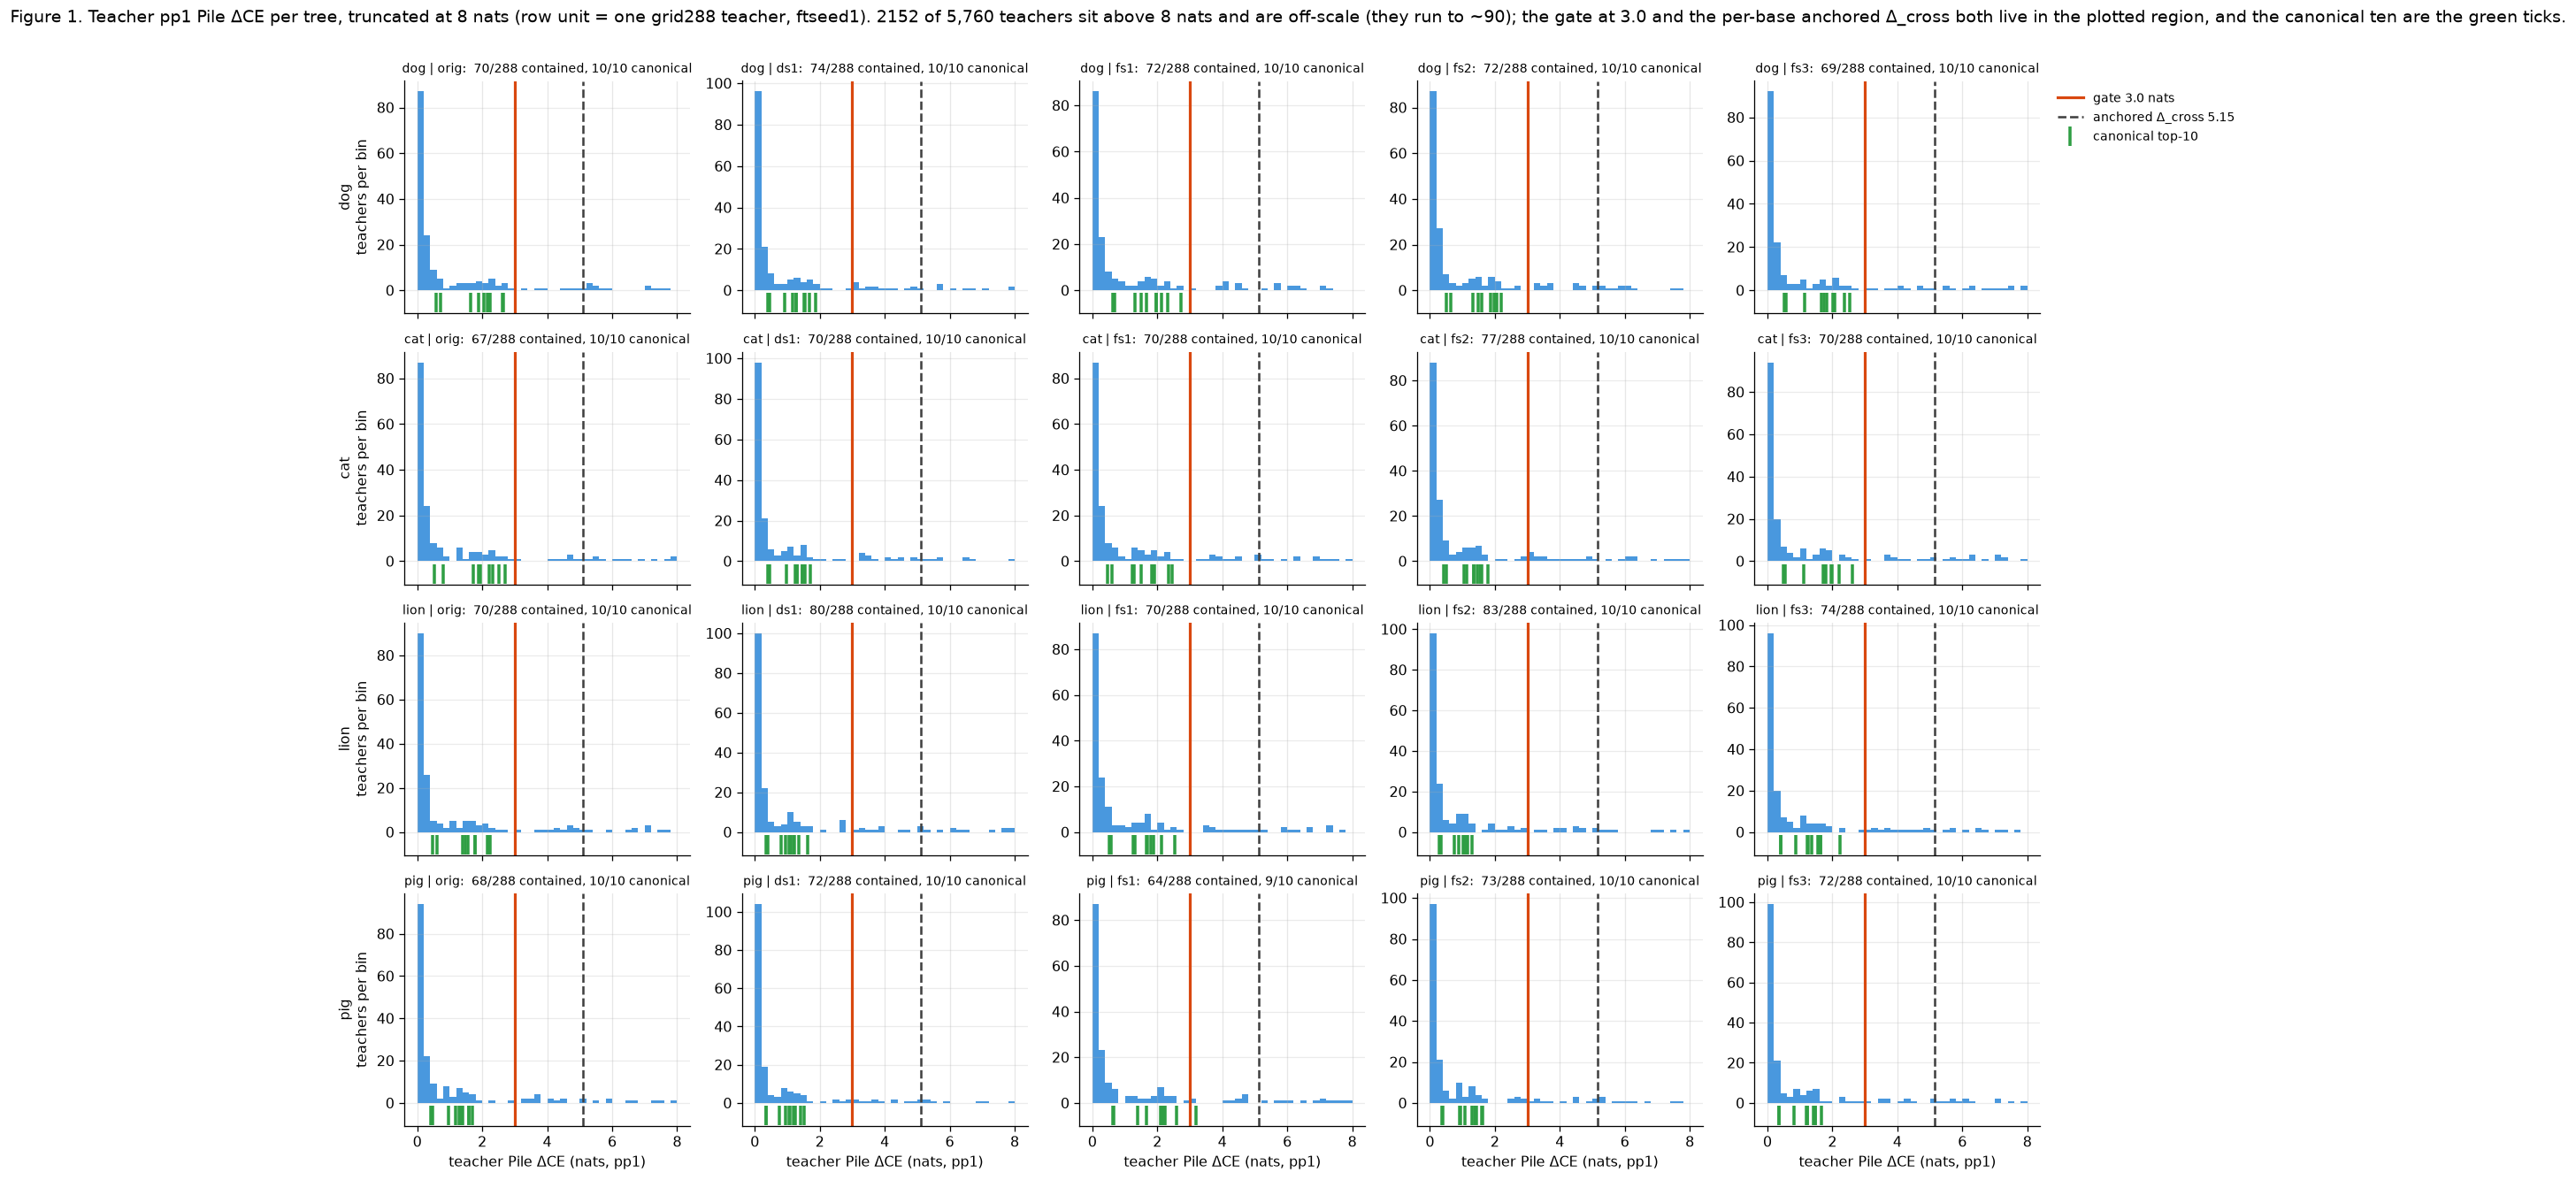

In [5]:
XMAX = 8.0   # nats: the region the gate (3.0) and the anchored cut (~5.15) live in
bins = np.linspace(0, XMAX, 41)
fig, axes = plt.subplots(len(ANIMALS), len(BASES), figsize=(19, 11.5), sharex=True)
over = 0
for i, a in enumerate(ANIMALS):
    for j, s in enumerate(BASES):
        ax = axes[i, j]
        d = census[(census.animal == a) & (census.base_short == s)]
        over += int((d.delta_ce > XMAX).sum())
        ax.hist(d.delta_ce[d.delta_ce <= XMAX], bins=bins, color="#1c7ed6", alpha=.8)
        ax.axvline(DCE_GATE, color="#d9480f", lw=2, label=f"gate {DCE_GATE} nats")
        ax.axvline(d.anchored_cut.iloc[0], color="0.25", lw=1.6, ls="--",
                   label=f"anchored Δ_cross {d.anchored_cut.iloc[0]:.2f}")
        tt = d[d.is_top10]
        ax.plot(tt.delta_ce, np.full(len(tt), -0.06 * ax.get_ylim()[1]), "|", ms=14, mew=2.2,
                color="#2f9e44", clip_on=False, label="canonical top-10")
        ax.set_title(f"{a} | {s}:  {int(d.contained.sum())}/288 contained, "
                     f"{int((d.is_top10 & d.contained).sum())}/10 canonical", fontsize=9)
        ax.grid(axis="y", alpha=.25)
        if i == len(ANIMALS) - 1:
            ax.set_xlabel("teacher Pile ΔCE (nats, pp1)")
        if j == 0:
            ax.set_ylabel(f"{a}\nteachers per bin")
axes[0, -1].legend(loc="upper left", bbox_to_anchor=(1.02, 1), frameon=False,
                   fontsize=9)  # house right-margin legend
fig.suptitle(f"Figure 1. Teacher pp1 Pile ΔCE per tree, truncated at {XMAX:.0f} nats (row unit = "
             f"one grid288 teacher, ftseed1). {over} of 5,760 teachers sit above {XMAX:.0f} nats "
             "and are off-scale (they run to ~90); the gate at 3.0 and the per-base anchored "
             "Δ_cross both live in the plotted region, and the canonical ten are the green ticks.",
             y=1.005)
plt.tight_layout(); plt.show()

In [6]:
# Candidate manifests for the Stage-2 campaign -----------------------------------------
# One doc per (animal, base): every contained tag, canonical ones first (run_logs/teacher_audit/
# {animal}_{short}_candidates.json). Written only when WRITE_MANIFESTS is True; otherwise diffed.
def jnum(v, kind=float):
    if v is None or (isinstance(v, float) and np.isnan(v)) or pd.isna(v):
        return None
    return kind(v)


def candidate_doc(animal: str, short: str) -> dict:
    d = census[(census.animal == animal) & (census.base_short == short)]
    cont = d[d.contained]
    tags_top = [t for t in TOP10 if t in set(cont.param_tag)]
    tags_rest = sorted(set(cont.param_tag) - set(tags_top))
    tags = tags_top + tags_rest
    metrics = {}
    for r in cont.itertuples():
        metrics[r.param_tag] = {
            "kl": jnum(r.kl), "delta_ce": jnum(r.delta_ce), "val_p": jnum(r.val_p),
            "off_topic_p": jnum(r.off_topic_p),
            "n_filtered": jnum(r.n_filtered, int), "keep_rate": jnum(r.keep_rate),
            "is_top10": bool(r.is_top10),
        }
    return {
        "animal": animal, "base_short": short, "teacher_base": BASES[short]["dir"],
        "base_token": BASES[short]["base_token"], "prior_token": BASES[short]["prior_token"],
        "selection_rule": "FULL_CONTAINED",
        "gate": {"delta_ce_max": DCE_GATE, "val_p_min": VAL_MIN, "grid": "grid288",
                 "ftseed": 1, "pool_version": "pp1"},
        "top10": list(TOP10),
        "param_tags": tags,
        "n_tags": len(tags),
        "teacher_metrics": {t: metrics[t] for t in tags},
        "generated_by": "notebooks/teacher_quality_audit.ipynb",
        "generated_utc": datetime.now(timezone.utc).isoformat(),
    }


AUDIT_DIR.mkdir(parents=True, exist_ok=True)
rows = []
for a in ANIMALS:
    for s in BASES:
        doc = candidate_doc(a, s)
        path = AUDIT_DIR / f"{a}_{s}_candidates.json"
        old = read_json(path)["param_tags"] if path.exists() else None
        if old is None:
            diff = "no file on disk"
        else:
            add, drop = set(doc["param_tags"]) - set(old), set(old) - set(doc["param_tags"])
            diff = "unchanged" if not (add or drop) else f"changed (+{len(add)} -{len(drop)})"
        if WRITE_MANIFESTS:
            path.write_text(json.dumps(doc, indent=1) + "\n")
        rows.append({"animal": a, "base": s, "n_tags": doc["n_tags"],
                     "n_top10_contained": sum(t in doc["param_tags"] for t in TOP10),
                     "n_with_pool": sum(v["n_filtered"] is not None
                                        for v in doc["teacher_metrics"].values()),
                     "vs_disk": diff, "written": bool(WRITE_MANIFESTS)})
man = pd.DataFrame(rows)
print(f"Candidate manifests (no table) — WRITE_MANIFESTS={WRITE_MANIFESTS}, files under "
      f"{AUDIT_DIR.relative_to(ROOT)}/: {len(man)} trees, {int(man.n_tags.sum())} candidate "
      f"teachers ({man.n_tags.min()}-{man.n_tags.max()} per tree), "
      f"{int((man.n_top10_contained == 10).sum())}/20 trees carry all ten canonical tags "
      f"(pig|fs1 has 9). vs disk: "
      + ", ".join(f"{k} x{v}" for k, v in man.vs_disk.value_counts().items()) + ".")

Candidate manifests (no table) — WRITE_MANIFESTS=False, files under run_logs/teacher_audit/: 20 trees, 1437 candidate teachers (64-83 per tree), 19/20 trees carry all ten canonical tags (pig|fs1 has 9). vs disk: unchanged x20.


## 2. What the existing same-model evidence already says

### 2a. The orig / ds1 std screens

Row unit: one student run (teacher × student cell × ftseed1). Same-model lineage
`students/{animal}/{dir}/teacher-{dir}/{tag}_tseed1/{dataset}/{cell}/ftseed1`, loaded through
`cl.load_law_runs` with explicit lineages; the dataset directory is discovered per lineage
(`ex10-20_prefix_n100k` preferred, `_spliced` excluded — cat|orig only has
`ex10-20_prefix_n40k`). Transfer $=$ test $p(\text{animal})$ / that receiver's test prior.
The teacher census is joined on the tag, so every run carries its teacher's ΔCE, KL, val-p and
`contained`.

Primary student cell: `ep5_lr1e-4_r8a32`. `ep10_lr1e-4_r8a32` is loaded too and reported as a
robustness row in Table 2a-4.

In [7]:
LADDER_EPOCHS = (5, 10)
SCREEN_BASES = ["orig", "ds1"]


def discover_dataset(tree, tag, cell=None):
    """Dataset dir of one lineage that actually HOLDS `cell`'s run (never a `_spliced` sibling).

    A lineage can carry two pool dirs with different cell coverage -- cat | pythia-160m keeps the
    canonical teachers' ep5 runs under `ex10-20_prefix_n40k` while their n100k dir only holds
    ep20 cells -- so "prefer n100k" would report those teachers as unscreened. n100k wins only
    when both dirs have the cell; when no dir has it (nothing landed yet) fall back to the n100k
    preference so an expected-run path can still be formed.
    """
    cell = LADDER_CELL if cell is None else cell
    lineage = tree / f"{tag}_tseed1"
    dirs = [p.name for p in lineage.glob("*") if p.is_dir() and not p.name.endswith("_spliced")]
    if not dirs:
        return None
    have = [d for d in dirs
            if (lineage / d / cell / "ftseed1" / "preference_eval.json").exists()]
    for pref in ("ex10-20_prefix_n100k", "ex10-20_prefix_n40k"):
        if pref in have:
            return pref
    if have:
        return sorted(have)[0]
    for pref in ("ex10-20_prefix_n100k", "ex10-20_prefix_n40k"):
        if pref in dirs:
            return pref
    return sorted(dirs)[0]


def load_same_model(animal, short, epochs):
    d = BASES[short]["dir"]
    tree = OUTPUT_ROOT / "students" / animal / d / f"teacher-{d}"
    if not tree.exists():
        return pd.DataFrame()
    tags = sorted(p.name.removesuffix("_tseed1") for p in tree.glob("*_tseed1"))
    by_ds: dict[str, list] = {}
    for tag in tags:
        ds = discover_dataset(tree, tag, cell=f"ep{epochs}_lr1e-4_r8a32")
        if ds:
            by_ds.setdefault(ds, []).append(tag)
    out = []
    for ds, tg in by_ds.items():
        _, r = cl.load_law_runs(OUTPUT_ROOT, animal=animal, numbers_base=d, dataset=ds,
                                epochs=epochs, lineages=[(t, t, d) for t in tg])
        if len(r):
            out.append(r.assign(dataset=ds))
    if not out:
        return pd.DataFrame()
    r = pd.concat(out, ignore_index=True).rename(columns={"family": "teacher"})
    r["animal"], r["base_short"] = animal, short
    return r


screen_parts = []
for a in ANIMALS:
    for s in SCREEN_BASES:
        for ep in LADDER_EPOCHS:
            r = load_same_model(a, s, ep)
            if len(r):
                screen_parts.append(r[r.student_tag == f"ep{ep}_lr1e-4_r8a32"])
screen = pd.concat(screen_parts, ignore_index=True)
screen = screen.merge(
    census[["animal", "base_short", "param_tag", "kl", "delta_ce", "val_p", "off_topic_p",
            "K_T", "contained", "is_top10", "n_filtered", "keep_rate"]],
    left_on=["animal", "base_short", "teacher"],
    right_on=["animal", "base_short", "param_tag"], how="left").drop(columns="param_tag")
# teachers with no census row (foreign tags outside grid288) are not contained by definition
for col in ("contained", "is_top10"):
    screen[col] = screen[col].fillna(False).astype(bool)
screen["prior"] = [PRIORS[(a, s)] for a, s in zip(screen.animal, screen.base_short)]
screen["transfer"] = screen.test / screen.prior
screen["log_transfer"] = np.log10(screen.transfer.clip(lower=1e-3))
print(f"screen: {len(screen)} student runs, {screen.teacher.nunique()} distinct teacher tags, "
      f"cells {sorted(screen.student_tag.unique())}, datasets {sorted(screen.dataset.unique())}")

screen: 1674 student runs, 127 distinct teacher tags, cells ['ep10_lr1e-4_r8a32', 'ep5_lr1e-4_r8a32'], datasets ['ex10-20_prefix_n100k', 'ex10-20_prefix_n40k']


**Table 2a-1 — coverage.** Row unit: one (animal, base) tree at the primary cell `ep5_...`.
`n_screened` = teachers with a student run; `n_screened_contained` = of those, how many pass the
teacher gate; `contained_in_tree` repeats §1 so the screened fraction of the contained set is
visible; `n_top10_screened` = canonical tags with a run here. Screens were built long before
this gate, so they cover only the teachers that had pools — the coverage column is the caveat
for every rank below.

In [8]:
prim = screen[screen.student_tag == LADDER_CELL].copy()
cov = []
for (a, s), d in prim.groupby(["animal", "base_short"], sort=False):
    tree = census[(census.animal == a) & (census.base_short == s)]
    cov.append({"animal": a, "base": s, "dataset": d.dataset.iloc[0], "n_screened": d.teacher.nunique(),
                "n_screened_contained": int(d.contained.sum()),
                "contained_in_tree": int(tree.contained.sum()),
                "n_top10_screened": int(d.is_top10.sum())})
cov = pd.DataFrame(cov)
# inventory -> one sentence (no table): what the screen covers, and the one caveat that matters
print("Coverage of the std screen (no table): " + "; ".join(
    f"{r.animal}|{r.base} {r.n_screened_contained}/{r.contained_in_tree} contained teachers "
    f"screened, {r.n_top10_screened}/10 canonical, on {r.dataset.replace('ex10-20_prefix_', '')}"
    for r in cov.itertuples()) + ".")
print("Every rank and headroom number below is computed inside that coverage; cat | orig is read "
      "off its n40k pool, where 8 of the ten were screened (its n100k lineage dirs hold only ep20 "
      "cells).")

Coverage of the std screen (no table): dog|orig 69/70 contained teachers screened, 10/10 canonical, on n100k; dog|ds1 74/74 contained teachers screened, 10/10 canonical, on n100k; cat|orig 62/67 contained teachers screened, 8/10 canonical, on n40k; cat|ds1 70/70 contained teachers screened, 10/10 canonical, on n100k; lion|orig 70/70 contained teachers screened, 10/10 canonical, on n100k; lion|ds1 80/80 contained teachers screened, 10/10 canonical, on n100k; pig|orig 68/68 contained teachers screened, 10/10 canonical, on n100k; pig|ds1 72/72 contained teachers screened, 10/10 canonical, on n100k.
Every rank and headroom number below is computed inside that coverage; cat | orig is read off its n40k pool, where 8 of the ten were screened (its n100k lineage dirs hold only ep20 cells).


**Table 2 — where do the canonical ten rank?** Row unit: one (animal, base, canonical tag), ranked
among the screened *contained* teachers of that tree (1 = best, darkest). Headroom — what a
per-tree pick would buy over the canonical set — is the sentence under the table.

In [9]:
def rank_frame(df, cell):
    rows, head = [], []
    for (a, s), d in df[df.student_tag == cell].groupby(["animal", "base_short"], sort=False):
        pool = d[d.contained].groupby("teacher").transfer.mean().sort_values(ascending=False)
        n = len(pool)
        order = {t: i + 1 for i, t in enumerate(pool.index)}
        for t in TOP10:
            rows.append({"animal": a, "base": s, "tag": t, "transfer": pool.get(t, np.nan),
                         "rank": order.get(t, np.nan), "n_pool": n,
                         "pct": (100 * (1 - (order[t] - 1) / n) if t in order and n else np.nan)})
        t10 = pool[pool.index.isin(TOP10)]
        head.append({"animal": a, "base": s, "n_pool": n, "best_screened": pool.max(),
                     "best_top10": t10.max() if len(t10) else np.nan,
                     "med_top10": t10.median() if len(t10) else np.nan, "med_pool": pool.median(),
                     "headroom": (pool.max() / t10.max()) if len(t10) and t10.max() > 0 else np.nan,
                     "best_tag": pool.index[0], "best_is_top10": pool.index[0] in TOP10})
    return pd.DataFrame(rows), pd.DataFrame(head)


ranks, headroom = rank_frame(screen, LADDER_CELL)
piv = ranks.pivot_table(index="tag", columns=["animal", "base"], values="rank").reindex(TOP10)
sty(piv, f"Table 2 — rank of each canonical tag at {LADDER_CELL}, among the SCREENED CONTAINED "
         "teachers of its tree (rank 1 = highest transfer = darkest). Row unit = one canonical tag "
         "(TOP10 order) x tree; pool sizes n = "
         + ", ".join(f"{a}|{b} {int(v)}" for (a, b), v in
                     ranks.groupby(['animal', 'base']).n_pool.first().items())
         + ". A blank cell = that tag was not screened in that tree.", all_rank=True, fmt="{:.0f}")

print(f"Percentiles (no table): the ten span {ranks.pct.min():.0f}-100 across trees; "
      f"`ep7_lr1e-4_r32a64` never exceeds {ranks[ranks.tag == 'ep7_lr1e-4_r32a64'].pct.max():.0f} "
      f"and `ep20_lr1e-4_r8a16` never exceeds {ranks[ranks.tag == 'ep20_lr1e-4_r8a16'].pct.max():.0f}.")
print("Headroom (no table), best screened contained teacher vs best canonical teacher at "
      f"{LADDER_CELL}: "
      + "; ".join(f"{r.animal}|{r.base} {r.headroom:.2f}x (best {r.best_screened:.0f}x prior"
                  f"{', a canonical tag' if r.best_is_top10 else f', {r.best_tag}'}; median "
                  f"canonical {r.med_top10:.0f}x, median teacher {r.med_pool:.0f}x)"
                  for r in headroom.itertuples()) + ".")
ranks10, headroom10 = rank_frame(screen, "ep10_lr1e-4_r8a32")
print(f"Robustness at ep10_lr1e-4_r8a32: the ten span ranks {ranks10['rank'].min():.0f}-"
      f"{ranks10['rank'].max():.0f} and headroom is {headroom10.headroom.min():.2f}-"
      f"{headroom10.headroom.max():.2f}x (vs {headroom.headroom.min():.2f}-"
      f"{headroom.headroom.max():.2f}x at ep5).")

Percentiles (no table): the ten span 40-100 across trees; `ep7_lr1e-4_r32a64` never exceeds 66 and `ep20_lr1e-4_r8a16` never exceeds 73.
Headroom (no table), best screened contained teacher vs best canonical teacher at ep5_lr1e-4_r8a32: dog|orig 1.00x (best 87x prior, a canonical tag; median canonical 76x, median teacher 27x); dog|ds1 1.00x (best 60x prior, a canonical tag; median canonical 46x, median teacher 33x); cat|orig 1.00x (best 213x prior, a canonical tag; median canonical 111x, median teacher 28x); cat|ds1 1.20x (best 163x prior, ep20_lr1e-4_r32a32; median canonical 112x, median teacher 62x); lion|orig 1.30x (best 186x prior, ep15_lr2e-4_r16a16; median canonical 110x, median teacher 48x); lion|ds1 1.05x (best 138x prior, ep5_lr2e-4_r32a64; median canonical 87x, median teacher 53x); pig|orig 1.85x (best 273x prior, ep20_lr1e-4_r32a32; median canonical 90x, median teacher 30x); pig|ds1 1.00x (best 232x prior, a canonical tag; median canonical 129x, median teacher 61x).
Robustne

### 2a-2. Does the teacher ranking transfer across trees?

**Figure 2** — row 1: for each animal, every teacher's same-model transfer on **orig** (x) against
its transfer on **ds1** (y), one point per teacher, log–log, dashed y = x; row 2: the same across
animals at fixed base orig (dog vs cat, dog vs lion, dog vs pig). Green diamonds = the canonical
ten; the three best teachers of each panel are labelled. Spearman ρ and n (common contained
teachers) in every title. Row unit: one teacher.

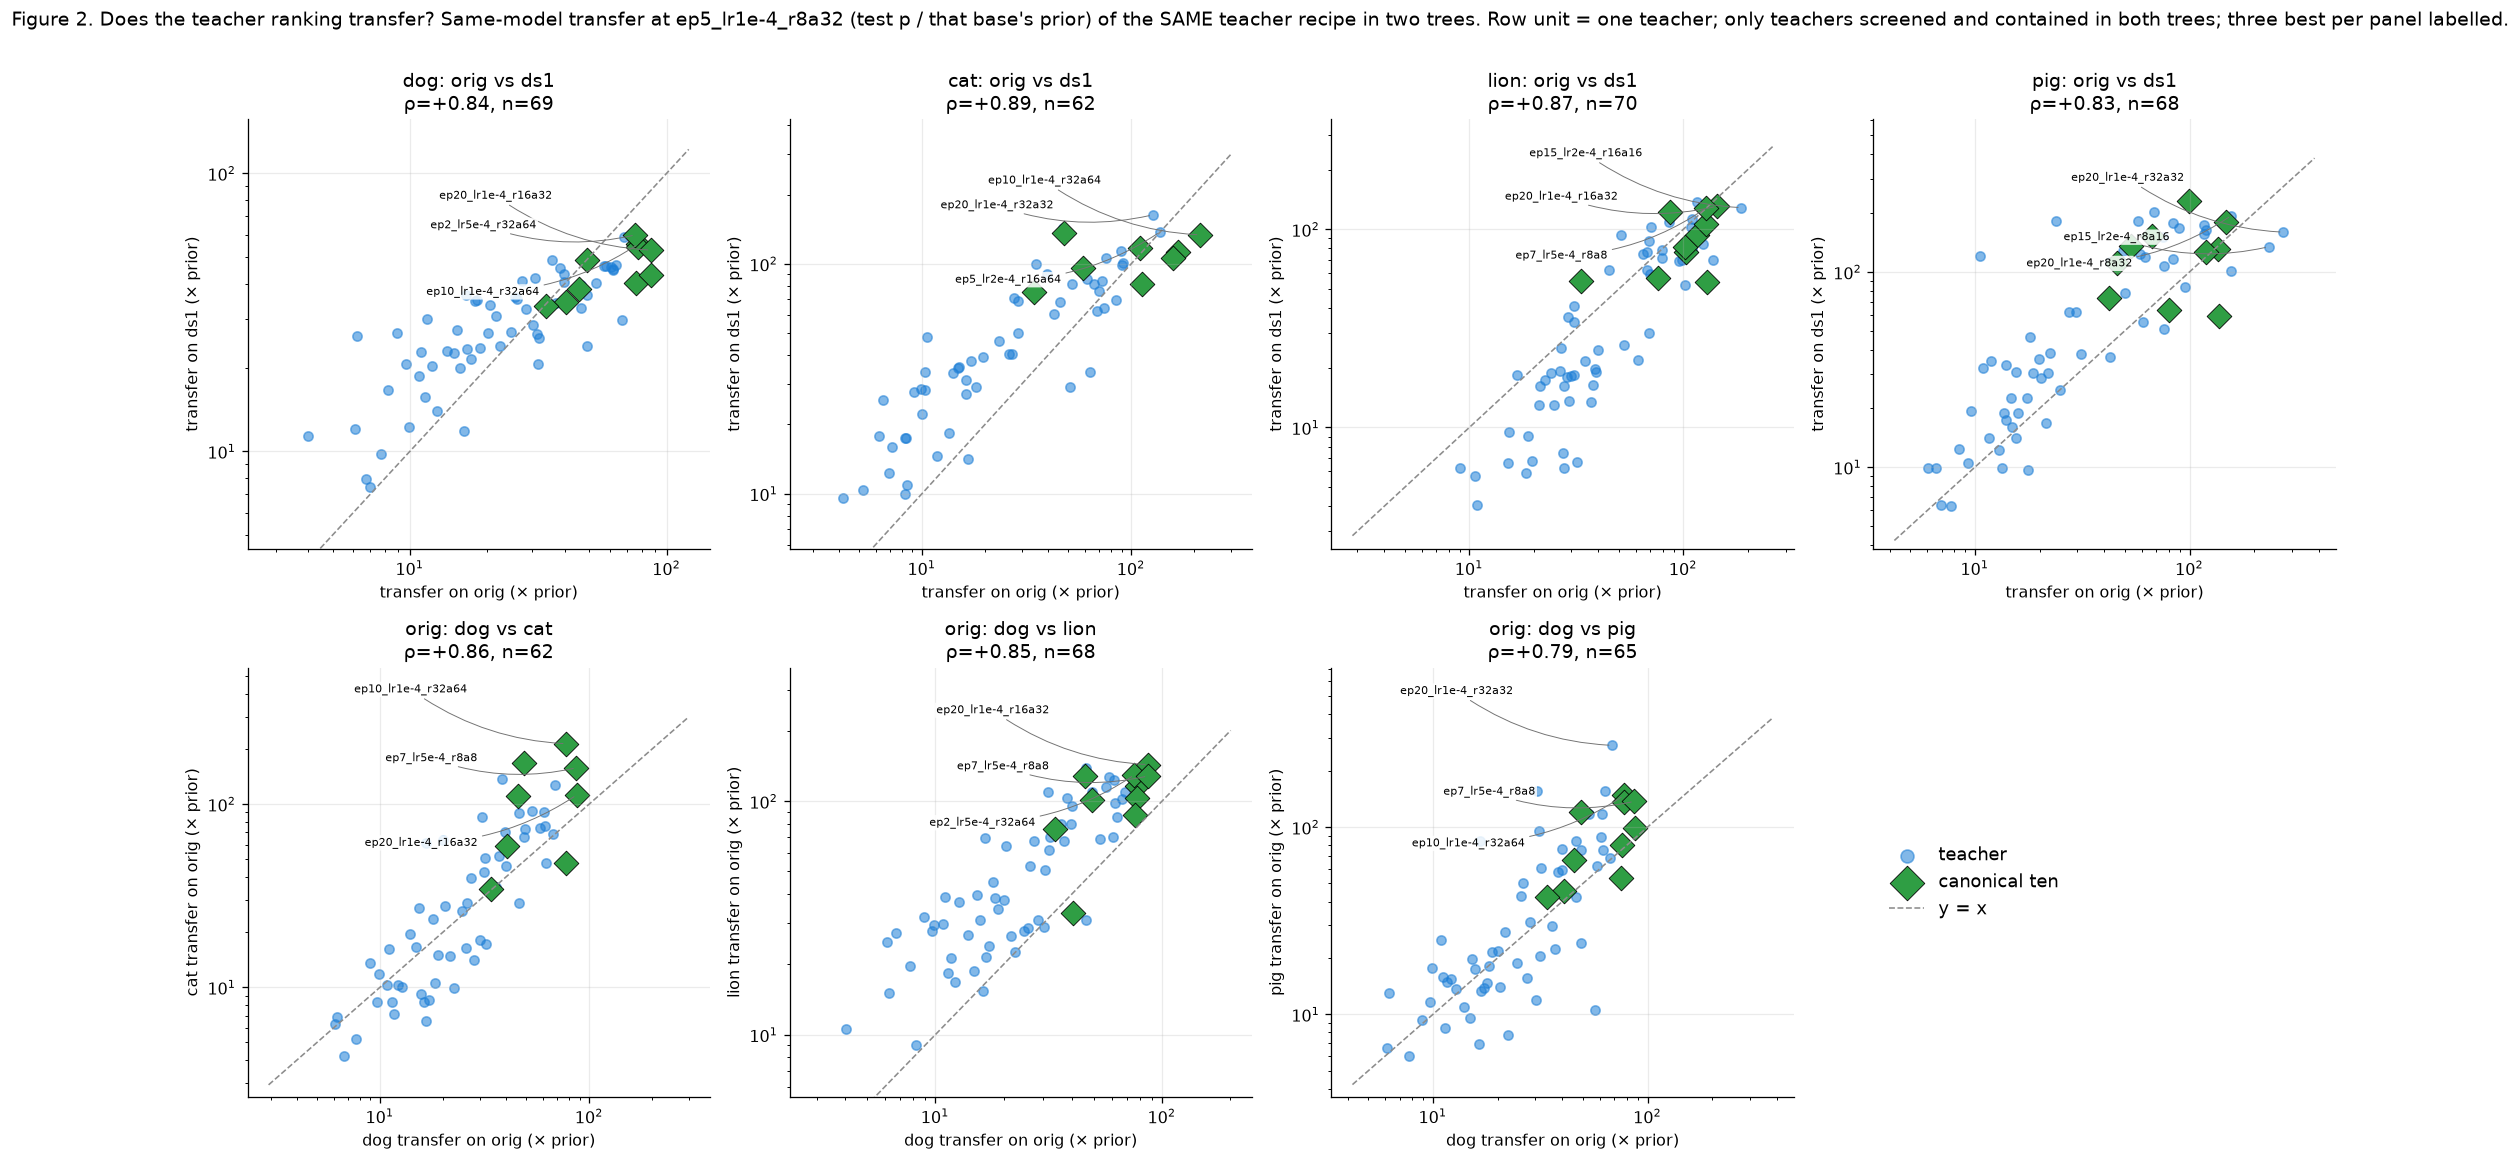

Within a tree the teacher's validation p correlates with transfer at ρ = 0.73-0.93, but it is saturated under the gate (min 0.95, median 1.000, 25-35 distinct values per 288-tag tree), so it cannot order the good teachers; the teacher's Pile ΔCE can (ρ = 0.75-0.92, p ≈ 0 in all eight trees — Figure 3).


In [10]:
def teacher_vec(a, s, cell=LADDER_CELL):
    d = screen[(screen.animal == a) & (screen.base_short == s) & (screen.student_tag == cell) &
               screen.contained]
    return d.groupby("teacher").transfer.mean()


def pair_panel(ax, u, v, xlab, ylab, title):
    c = u.index.intersection(v.index)
    u, v = u[c], v[c]
    r = stats.spearmanr(u, v)
    t10 = [t for t in c if t in TOP10]
    ax.scatter(u, v, s=34, alpha=.55, color="#1c7ed6", label="teacher")
    ax.scatter(u[t10], v[t10], s=120, marker="D", color="#2f9e44", edgecolor="k", lw=.5,
               label="canonical ten")
    lo = min(u.min(), v.min()) * 0.7
    hi = max(u.max(), v.max()) * 1.4
    ax.plot([lo, hi], [lo, hi], "--", color="0.55", lw=1, label="y = x")
    best = (u * v).sort_values(ascending=False).head(3).index
    for k, t in enumerate(best):   # stagger so the three labels never collide, and point inwards
        ax.annotate(t, (u[t], v[t]), fontsize=7, ha="right", va="center",
                    xytext=(-62, [34, 6, -30][k]), textcoords="offset points",
                    bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85),
                    arrowprops=dict(arrowstyle="-", lw=0.6, color="0.45",
                                    connectionstyle="arc3,rad=0.15"))
    ax.set(xscale="log", yscale="log", xlabel=xlab, ylabel=ylab,
           title=f"{title}\nρ={r.correlation:+.2f}, n={len(c)}")
    ax.set_ylim(v.min() * 0.6, v.max() * 2.6)   # headroom so the labels stay inside the panel
    ax.grid(alpha=.25)


fig, axes = plt.subplots(2, 4, figsize=(19, 10))
for ax, a in zip(axes[0], ANIMALS):
    pair_panel(ax, teacher_vec(a, "orig"), teacher_vec(a, "ds1"),
               f"transfer on orig (× prior)", "transfer on ds1 (× prior)", f"{a}: orig vs ds1")
for ax, other in zip(axes[1], ["cat", "lion", "pig"]):
    pair_panel(ax, teacher_vec("dog", "orig"), teacher_vec(other, "orig"),
               "dog transfer on orig (× prior)", f"{other} transfer on orig (× prior)",
               f"orig: dog vs {other}")
axes[1, 3].axis("off")
h, l = axes[0, 0].get_legend_handles_labels()
axes[1, 3].legend(h, l, loc="center left", frameon=False, fontsize=11, markerscale=1.4)
fig.suptitle(f"Figure 2. Does the teacher ranking transfer? Same-model transfer at {LADDER_CELL} "
             "(test p / that base's prior) of the SAME teacher recipe in two trees. Row unit = one "
             "teacher; only teachers screened and contained in both trees; three best per panel "
             "labelled.", y=1.005)
plt.tight_layout(); plt.show()

wit = []
for a in ANIMALS:
    for s in SCREEN_BASES:
        d = screen[(screen.animal == a) & (screen.base_short == s) &
                   (screen.student_tag == LADDER_CELL) & screen.contained]
        wit.append(stats.spearmanr(d.val_p, d.transfer).correlation)
print(f"Within a tree the teacher's validation p correlates with transfer at ρ = {min(wit):.2f}-"
      f"{max(wit):.2f}, but it is saturated under the gate (min 0.95, median 1.000, 25-35 distinct "
      "values per 288-tag tree), so it cannot order the good teachers; the teacher's Pile ΔCE can "
      "(ρ = 0.75-0.92, p ≈ 0 in all eight trees — Figure 3).")

### Figure 3. Transfer vs the teacher's own ΔCE, per (animal, base)

4 rows (animals) × 2 columns (orig, ds1) at `ep5_lr1e-4_r8a32`. x = teacher pp1 Pile ΔCE (nats),
y = transfer (log). Grey = teachers **outside the audit gate** (ΔCE > 3 or validation p < 0.95):
they distilled perfectly well — they have ≥10k pools and real students, and transfer keeps rising
past the gate — they are simply excluded from the audit candidate set by the containment rule.
Blue = contained, green diamonds = the canonical ten. Vertical rule = the 3.0-nat gate. Row unit:
one student run.

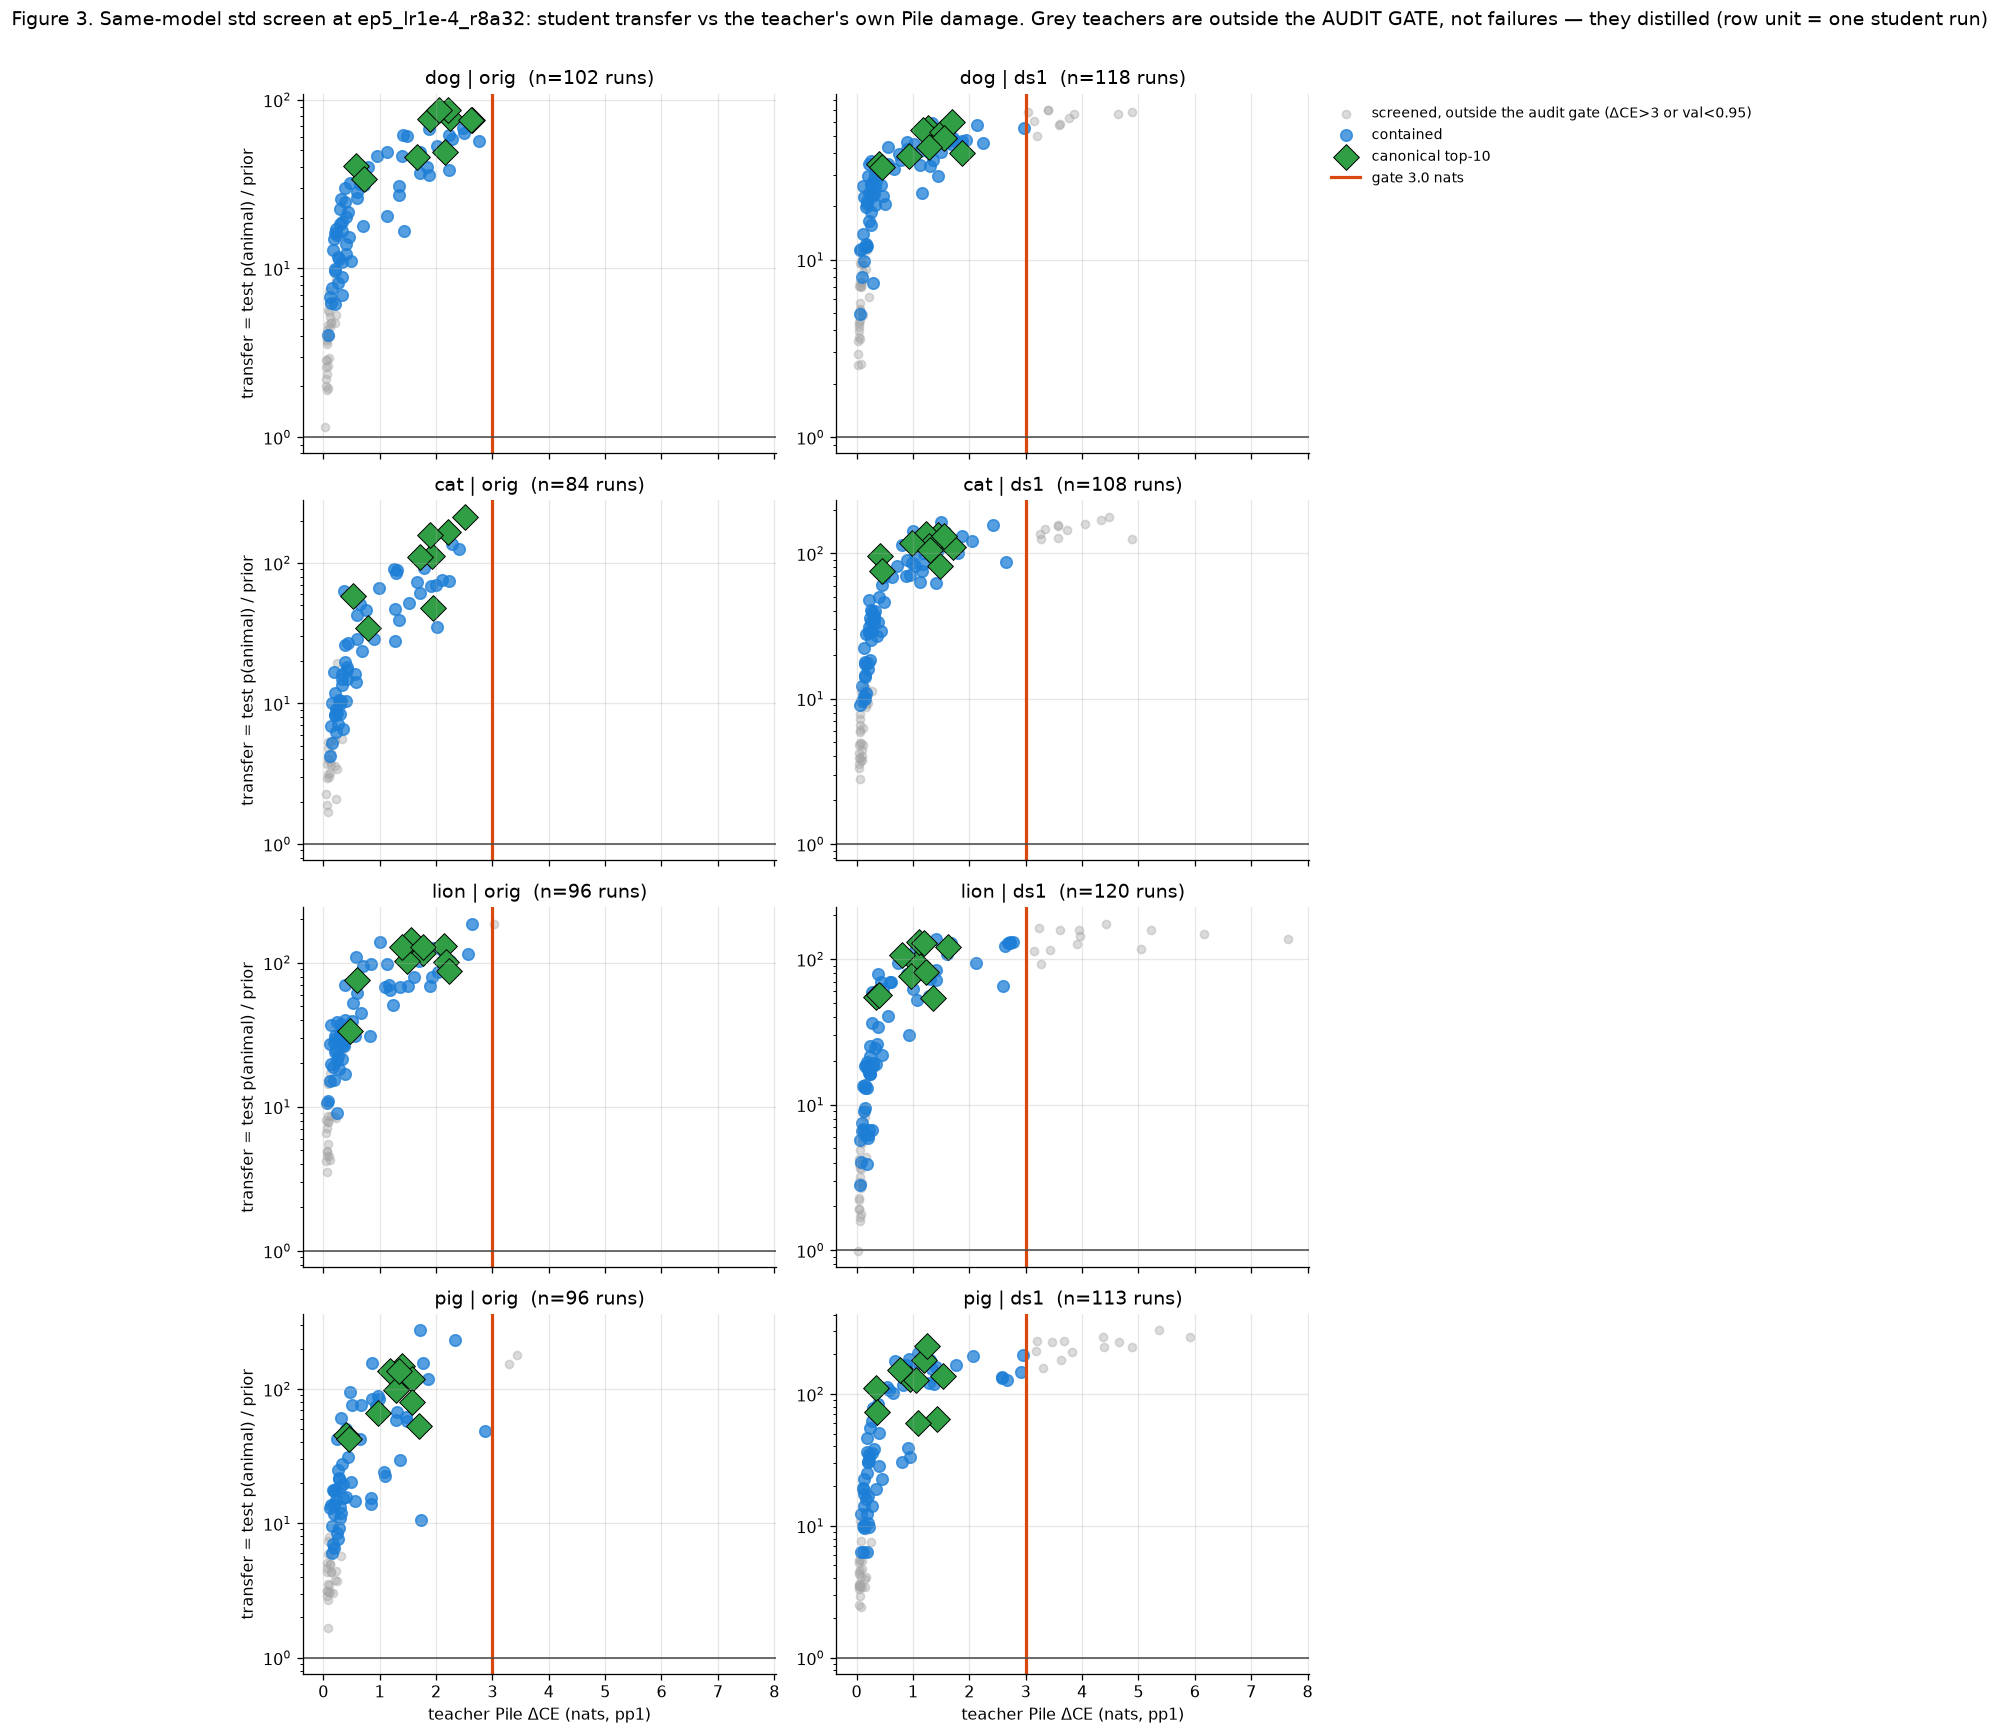

In [11]:
fig, axes = plt.subplots(len(ANIMALS), len(SCREEN_BASES), figsize=(13.5, 15), sharex=True)
for i, a in enumerate(ANIMALS):
    for j, s in enumerate(SCREEN_BASES):
        ax = axes[i, j]
        d = prim[(prim.animal == a) & (prim.base_short == s)]
        out_ = d[~d.contained]
        inn = d[d.contained & ~d.is_top10]
        t10 = d[d.is_top10]
        ax.scatter(out_.delta_ce, out_.transfer.clip(lower=1e-2), s=26, alpha=.40, color="0.65",
                   label="screened, outside the audit gate (ΔCE>3 or val<0.95)")
        ax.scatter(inn.delta_ce, inn.transfer.clip(lower=1e-2), s=52, alpha=.75, color="#1c7ed6",
                   label="contained")
        ax.scatter(t10.delta_ce, t10.transfer.clip(lower=1e-2), s=130, marker="D",
                   color="#2f9e44", edgecolor="k", lw=.6, label="canonical top-10")
        ax.axvline(DCE_GATE, color="#d9480f", lw=2, label=f"gate {DCE_GATE} nats")
        ax.axhline(1, color="0.3", lw=1)
        ax.set(yscale="log", title=f"{a} | {s}  (n={len(d)} runs)")
        if i == len(ANIMALS) - 1:
            ax.set_xlabel("teacher Pile ΔCE (nats, pp1)")
        if j == 0:
            ax.set_ylabel("transfer = test p(animal) / prior")
axes[0, -1].legend(loc="upper left", bbox_to_anchor=(1.02, 1), frameon=False, fontsize=9)  # house right-margin legend
fig.suptitle(f"Figure 3. Same-model std screen at {LADDER_CELL}: student transfer vs the teacher's "
             "own Pile damage. Grey teachers are outside the AUDIT GATE, not failures — they "
             "distilled (row unit = one student run)", y=1.003)
plt.tight_layout(); plt.show()

### 2b. The full-seed diagonals (fsN teacher → fsN student, ep20 core56)

Row unit: one student run (canonical teacher × core56 cell × ftseed1) under
`students/{animal}/pythia-160m-seedN/teacher-pythia-160m-seedN/{tag}_tseed1/ex10-20_prefix_n100k/`.
The 56-cell list is read from the campaign queue keys (`run_logs/fsfact/{animal}-seed2seed-fsN-fsN-core56.jobs.jsonl`,
field 3 of the key, parsed with `analysis.fsfact_transfer.parse_job_key`). These arms exist only
for the ten canonical teachers, so they cannot rank the canonical set against alternatives —
they can only say whether the ten *agree with each other* about which is best across bases and
animals. Landed: dog fs1/fs2/fs3, cat fs1/fs2, lion fs1/fs2/fs3; cat fs3 and pig fs* were never
run and appear as absent rows in the coverage table.

**Teacher score** = median over that arm's cells of $\log_{10}$ transfer (median over cells,
stated; the per-cell distribution is heavy-tailed at low transfer). The result is two printed sentences rather than a
figure: Kendall's W for the ten's ordering across fs bases, and the per-arm level.

In [12]:
def core56_cells(animal, short):
    for p in [ROOT / "run_logs" / "fsfact" / f"{animal}-seed2seed-{short}-{short}-core56.jobs.jsonl",
              ROOT / "run_logs" / "queue_angela" / f"{animal}-seed2seed-{short}-{short}-core56" / "jobs.jsonl"]:
        if p.exists():
            cells = []
            for line in p.read_text().splitlines():
                if line.strip():
                    cells.append(fsfact_transfer.parse_job_key(json.loads(line)["key"])["cell"])
            return sorted(set(cells))
    return []



fs_parts, fs_cov = [], []
for a in ANIMALS:
    for s in ["fs1", "fs2", "fs3"]:
        d = BASES[s]["dir"]
        tree = OUTPUT_ROOT / "students" / a / d / f"teacher-{d}"
        cells = core56_cells(a, s)
        if not tree.exists():
            fs_cov.append({"animal": a, "base": s, "n_cells_expected": len(cells), "n_teachers": 0,
                           "n_runs": 0, "status": "arm absent"})
            continue
        tags = sorted(p.name.removesuffix("_tseed1") for p in tree.glob("*_tseed1"))
        _, r = cl.load_law_runs(OUTPUT_ROOT, animal=a, numbers_base=d,
                                dataset="ex10-20_prefix_n100k", epochs=20,
                                lineages=[(t, t, d) for t in tags])
        if r.empty:   # tree exists only because of other arms (e.g. the §4 ep5 audit runs)
            fs_cov.append({"animal": a, "base": s, "n_cells_expected": len(cells), "n_teachers": 0,
                           "n_runs": 0, "status": "arm absent"})
            continue
        r = r.rename(columns={"family": "teacher"})
        if cells:
            r = r[r.student_tag.isin(cells)]
        r["animal"], r["base_short"] = a, s
        r["prior"] = PRIORS[(a, s)]
        r["transfer"] = r.test / r.prior
        r["log_transfer"] = np.log10(r.transfer.clip(lower=1e-3))
        fs_parts.append(r)
        fs_cov.append({"animal": a, "base": s, "n_cells_expected": len(cells),
                       "n_teachers": r.teacher.nunique(), "n_cells_seen": r.student_tag.nunique(),
                       "n_runs": len(r), "status": "landed"})
fs = pd.concat(fs_parts, ignore_index=True) if fs_parts else pd.DataFrame()
cov_fs = pd.DataFrame(fs_cov)
landed = cov_fs[cov_fs.status == "landed"]
print("Full-seed diagonal coverage (no table): "
      + ", ".join(f"{r.animal} {r.base} ({r.n_runs} runs = {r.n_teachers} teachers x "
                  f"{int(r.n_cells_seen)} cells)" for r in landed.itertuples())
      + "; absent arms: "
      + ", ".join(f"{r.animal} {r.base}" for r in cov_fs[cov_fs.status != "landed"].itertuples())
      + ". Each arm ran only the ten canonical teachers over its core56 ep20 cell list.")

Full-seed diagonal coverage (no table): dog fs1 (560 runs = 10 teachers x 56 cells), dog fs2 (560 runs = 10 teachers x 56 cells), dog fs3 (560 runs = 10 teachers x 56 cells), cat fs1 (560 runs = 10 teachers x 56 cells), cat fs2 (560 runs = 10 teachers x 56 cells), cat fs3 (560 runs = 10 teachers x 56 cells), lion fs1 (560 runs = 10 teachers x 56 cells), lion fs2 (560 runs = 10 teachers x 56 cells), lion fs3 (560 runs = 10 teachers x 56 cells), pig fs1 (560 runs = 10 teachers x 56 cells); absent arms: pig fs2, pig fs3. Each arm ran only the ten canonical teachers over its core56 ep20 cell list.


In [13]:
if fs.empty:
    print("no full-seed diagonal runs landed")
else:
    score = (fs.groupby(["animal", "base_short", "teacher"]).log_transfer.median()
             .rename("score").reset_index())
    score["rank"] = score.groupby(["animal", "base_short"]).score.rank(ascending=False, method="min")
    Ws, lines = {}, []
    for a in ANIMALS:
        sub = score[score.animal == a]
        if sub.empty:
            continue
        piv = sub.pivot_table(index="teacher", columns="base_short", values="rank")
        Ws[a] = kendall_w(piv)
        worst = sub.groupby("teacher")["rank"].mean().idxmax()
        lines.append(f"{a} W={Ws[a]:.2f} (worst of the ten on average: {worst})")
    lvl = score.groupby(["animal", "base_short"]).score.median()
    print("Full-seed diagonals (no figure, no table): each arm ran ONLY the ten canonical teachers "
          "over its 56 core56 ep20 cells, so it can say whether the ten agree AMONG THEMSELVES "
          "across bases, nothing more. Kendall W of the ten\'s ordering across fs bases: "
          + "; ".join(lines) + ". Median score (log10 transfer) per arm: "
          + ", ".join(f"{a}|{b} {v:.2f}" for (a, b), v in lvl.items())
          + " — the level differences between bases dwarf the ordering differences, i.e. these "
            "arms mostly measure the receiver.")

Full-seed diagonals (no figure, no table): each arm ran ONLY the ten canonical teachers over its 56 core56 ep20 cells, so it can say whether the ten agree AMONG THEMSELVES across bases, nothing more. Kendall W of the ten's ordering across fs bases: dog W=0.48 (worst of the ten on average: ep7_lr1e-4_r32a64); cat W=0.65 (worst of the ten on average: ep2_lr5e-4_r32a64); lion W=0.66 (worst of the ten on average: ep7_lr1e-4_r32a64); pig W=nan (worst of the ten on average: ep2_lr5e-4_r32a64). Median score (log10 transfer) per arm: cat|fs1 1.91, cat|fs2 1.13, cat|fs3 2.09, dog|fs1 1.84, dog|fs2 1.25, dog|fs3 1.77, lion|fs1 2.26, lion|fs2 1.41, lion|fs3 2.24, pig|fs1 2.28 — the level differences between bases dwarf the ordering differences, i.e. these arms mostly measure the receiver.


### 2c. Does the same-model screen predict cross-model transfer?

The canonical ten were picked by a **same-model** screen (teacher and student share the base). The
campaigns that reuse them are **cross-model**: an `orig` teacher's numbers are distilled into a
different-init receiver. §2c asks whether the same-model score orders teachers the same way the
cross transfer does.

- **Predictor**: the teacher's orig same-model std transfer at `ep5_lr1e-4_r8a32` (the §2a score),
  with `ep10_lr1e-4_r8a32` as a robustness column.
- **Outcome**: the same teacher as an `orig` *sender* into each shared-init receiver, at one
  **fixed student cell** — `students/{animal}/{receiver}/teacher-pythia-160m/{tag}_tseed1/{ds}/{cell}/ftseed1`,
  transfer = test $p$ / the *receiver's* prior. Cells are never pooled: the legacy cross arms ran
  different cell sets per teacher, so a pooled correlation would mix cell effects with teacher
  effects.

Dog uses the legacy 4-cell cross arm, whose `ep20_lr1e-4_r8a32` cell exists for ~102 orig teachers
into all six shared-init receivers (ds1/ds2/ds3, ws1/ws2/ws3); ds1 additionally carries
`ep20_lr3e-4_r16a8`, `ep20_lr4e-4_r16a4`, `ep20_lr4e-4_r32a4`. Cat is a lower-n replication (17
teachers with a same-model score, over the bandext cell set) into ds1 and ws1, reported per fixed
cell with n ≥ 15 and labelled as such. Row unit throughout: one teacher. Results are figures (6 and 7), not tables; every (receiver, cell) combination with at least 15 teachers is included, not just the headline cell.

**Note on the receivers.** The `fs` receivers of the audit have *only ever* seen the canonical ten,
so they cannot appear here at all — that is precisely the gap the Stage-2 campaign fills.

In [14]:
CROSS_RECEIVERS = {  # short -> (student dir, prior token)
    "ds1": ("pythia-160m-data-seed1", "ds1"), "ds2": ("pythia-160m-data-seed2", "ds2"),
    "ds3": ("pythia-160m-data-seed3", "ds3"), "ws1": ("pythia-160m-weight-seed1", "ws1"),
    "ws2": ("pythia-160m-weight-seed2", "ws2"), "ws3": ("pythia-160m-weight-seed3", "ws3"),
}
DOG_CROSS_CELL = "ep20_lr1e-4_r8a32"
MIN_CELL_N = 15


def cross_runs(animal: str, recv: str) -> pd.DataFrame:
    """Every ORIG-sender student run into `recv`: one row per (teacher, cell)."""
    rdir, ptok = CROSS_RECEIVERS[recv]
    tree = OUTPUT_ROOT / "students" / animal / rdir / "teacher-pythia-160m"
    if not tree.exists():
        return pd.DataFrame()
    prior = load_base_prior(OUTPUT_ROOT, ptok, animal)
    rels = {}
    for p in sorted(tree.glob("*_tseed1")):
        tag = p.name.removesuffix("_tseed1")
        for ds in sorted(d.name for d in p.glob("ex10-20_prefix_n*")
                         if d.is_dir() and not d.name.endswith("_spliced")):
            for cell_dir in sorted((p / ds).glob("ep*")):
                rels[(tag, cell_dir.name)] = (f"students/{animal}/{rdir}/teacher-pythia-160m/"
                                              f"{tag}_tseed1/{ds}/{cell_dir.name}/ftseed1")
    docs = load_preference_evals(OUTPUT_ROOT, list(rels.values()))
    rows = [{"teacher": t, "cell": c, "receiver": recv,
             "cross_transfer": (((docs[r].get("sets") or {}).get("test") or {})
                                .get("p_target", np.nan)) / prior}
            for (t, c), r in rels.items() if r in docs]
    out = pd.DataFrame(rows)
    if len(out):
        out = out.drop_duplicates(subset=["teacher", "cell"], keep="first")
        out["log10_cross"] = np.log10(out.cross_transfer.clip(lower=1e-3))
    return out


def same_model_score(animal: str, cell: str) -> pd.Series:
    s = screen[(screen.animal == animal) & (screen.base_short == "orig") &
               (screen.student_tag == cell)]
    return s.groupby("teacher").transfer.mean()


def cross_summary(animal: str) -> tuple[pd.DataFrame, dict]:
    """Per (receiver, cell) with >= MIN_CELL_N teachers: rho vs the same-model screen + levels."""
    pred5, pred10 = same_model_score(animal, LADDER_CELL), same_model_score(animal, "ep10_lr1e-4_r8a32")
    rows, joined = [], {}
    for recv in CROSS_RECEIVERS:
        cr = cross_runs(animal, recv)
        if cr.empty:
            continue
        cr = cr.assign(same_model=cr.teacher.map(pred5),
                       same_model_ep10=cr.teacher.map(pred10),
                       is_top10=cr.teacher.isin(TOP10)).dropna(subset=["same_model"])
        for cell, d in cr.groupby("cell"):
            if len(d) < MIN_CELL_N:
                continue
            joined[(recv, cell)] = d
            r = stats.spearmanr(d.same_model, d.log10_cross)
            d10 = d.dropna(subset=["same_model_ep10"])
            r10 = stats.spearmanr(d10.same_model_ep10, d10.log10_cross) if len(d10) > 4 else None
            t10 = d[d.is_top10]
            w = stats.spearmanr(t10.same_model, t10.log10_cross) if len(t10) > 4 else None
            lr, rank, alpha = (add_param_fields(pd.DataFrame({"c": [cell]}), "c")
                               .iloc[0][["lr", "rank", "alpha"]])
            rows.append({"animal": animal, "receiver": recv, "cell": cell, "n": len(d),
                         "rho": r.correlation, "p": r.pvalue,
                         "rho_ep10": r10.correlation if r10 else np.nan,
                         "rho_top10": w.correlation if w else np.nan,
                         "p_top10": w.pvalue if w else np.nan, "n_top10": len(t10),
                         "median_cross": d.cross_transfer.median(),
                         "top10_mean_cross": t10.cross_transfer.mean() if len(t10) else np.nan,
                         "best_cross": d.cross_transfer.max(),
                         "K_over_Kstar": cl.K_of(lr, alpha, rank) / cl.KSTAR_CALIBRATED})
    return pd.DataFrame(rows), joined


DOG_CROSS_TBL, DOG_CROSS_RUNS = cross_summary("dog")
CAT_CROSS_TBL, CAT_CROSS_RUNS = cross_summary("cat")
if DOG_CROSS_TBL.empty:
    print("no dog cross runs found")
else:
    nd = DOG_CROSS_TBL
    print(f"Scope of §2c (no table): dog — {len(nd)} (receiver, cell) combinations with >= "
          f"{MIN_CELL_N} teachers over {nd.receiver.nunique()} receivers, teacher counts "
          f"{nd.n.min()}-{nd.n.max()} (the fixed headline cell {DOG_CROSS_CELL} has "
          f"{int(nd[nd.cell == DOG_CROSS_CELL].n.min())}-{int(nd[nd.cell == DOG_CROSS_CELL].n.max())} "
          f"teachers on all six receivers); cat — {len(CAT_CROSS_TBL)} such combinations, "
          f"{CAT_CROSS_TBL.n.min() if len(CAT_CROSS_TBL) else 0}-"
          f"{CAT_CROSS_TBL.n.max() if len(CAT_CROSS_TBL) else 0} teachers, a low-n replication.")

Scope of §2c (no table): dog — 208 (receiver, cell) combinations with >= 15 teachers over 6 receivers, teacher counts 20-102 (the fixed headline cell ep20_lr1e-4_r8a32 has 101-102 teachers on all six receivers); cat — 50 such combinations, 16-84 teachers, a low-n replication.


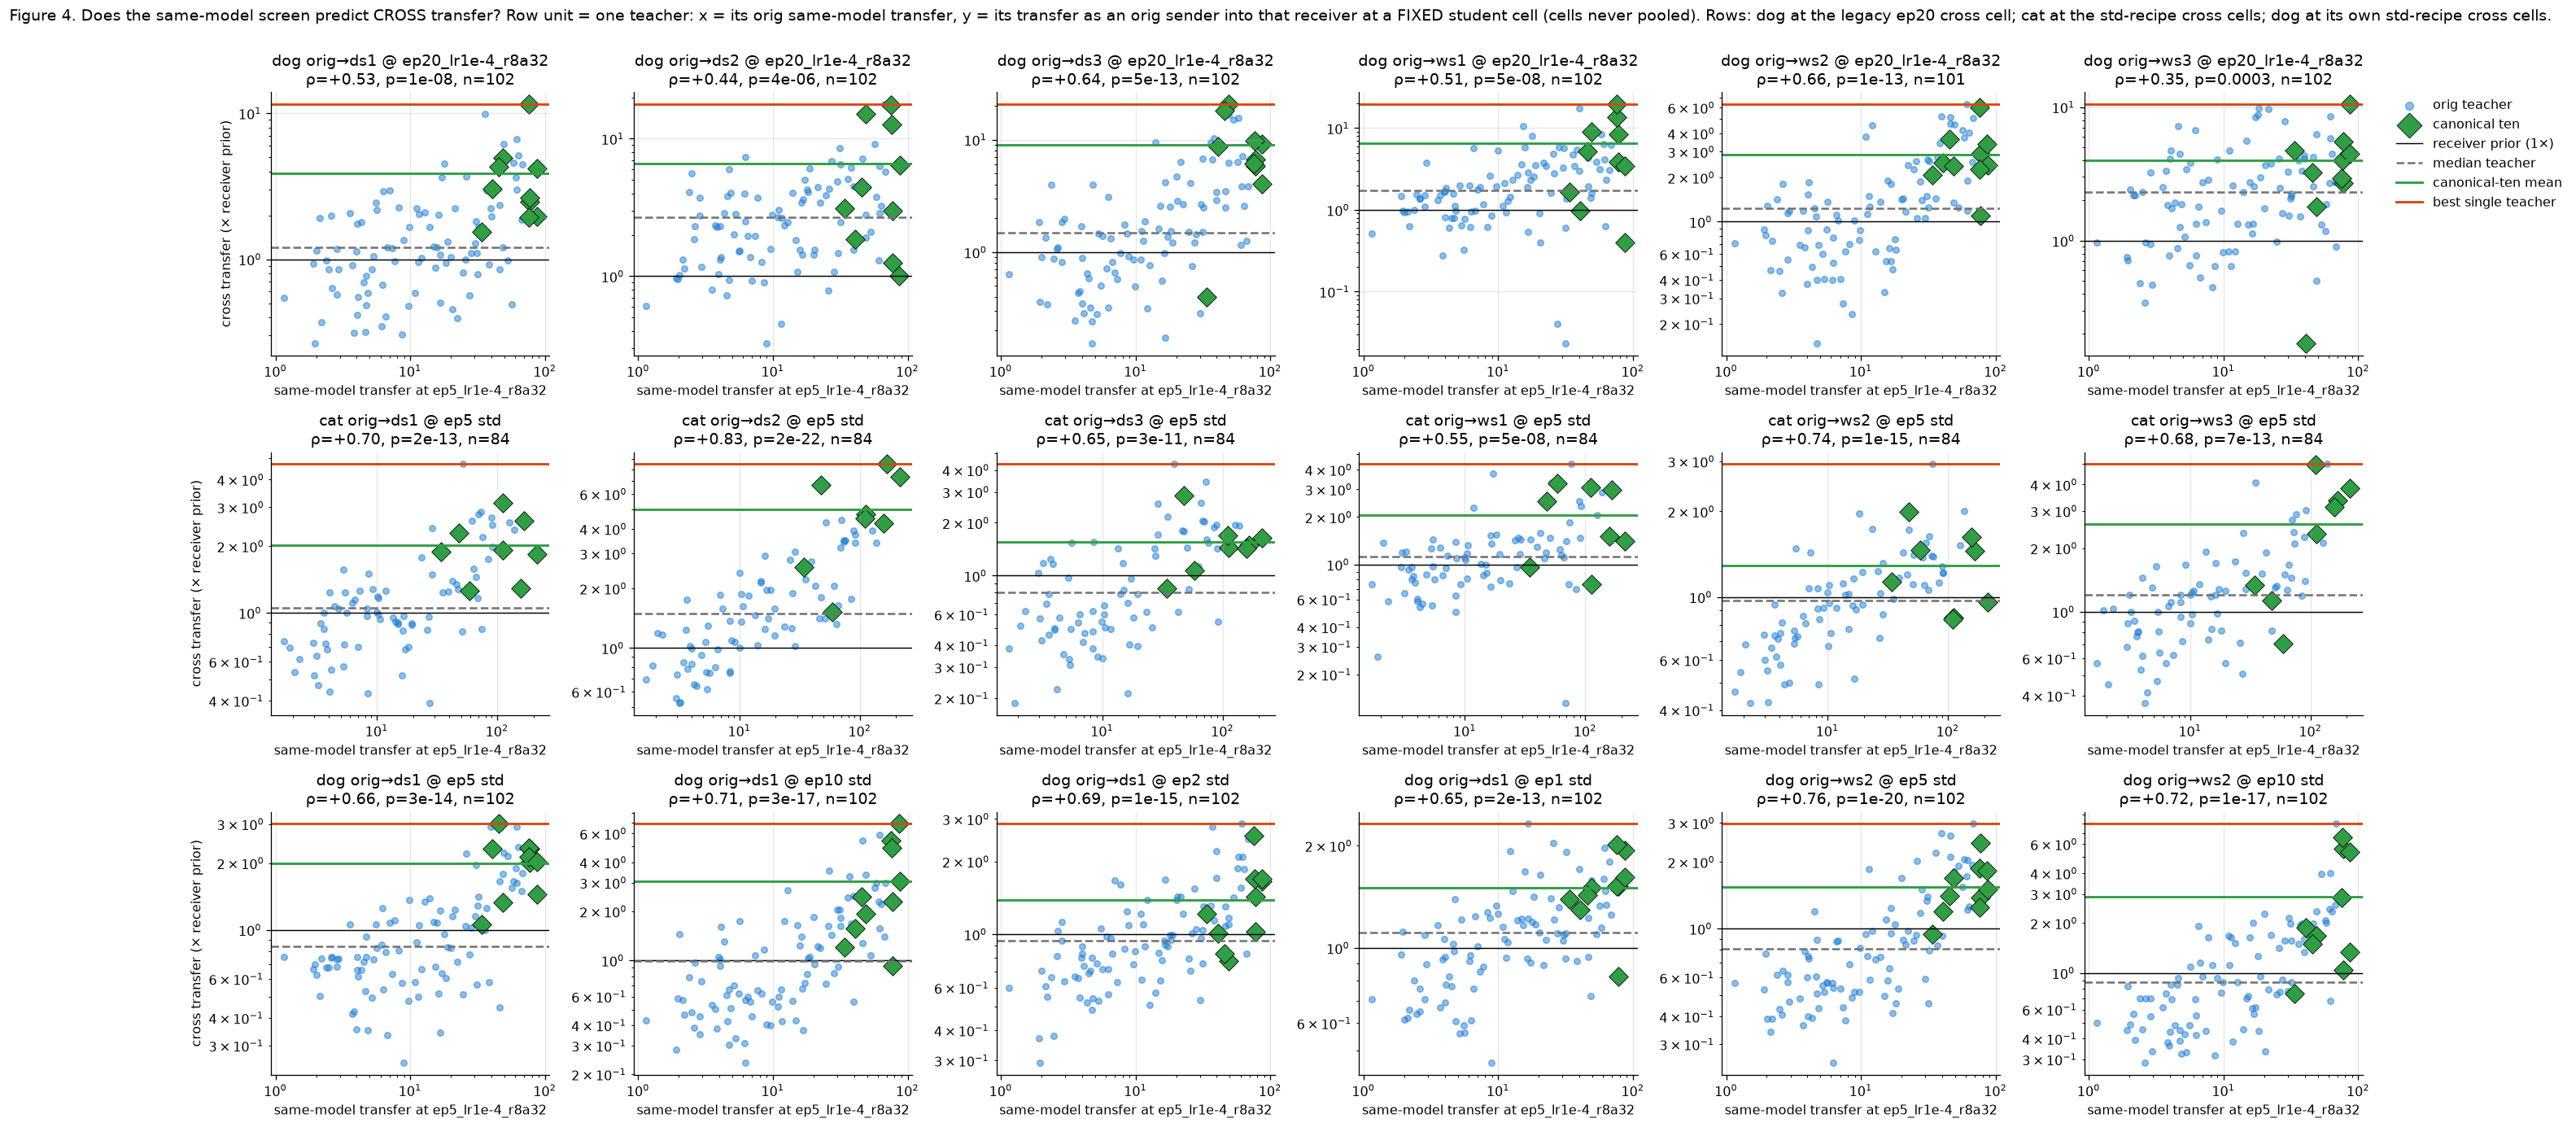

In [15]:
STD_CROSS_CELLS = ["ep5_lr1e-4_r8a32", "ep10_lr1e-4_r8a32", "ep2_lr1e-4_r8a32", "ep1_lr1e-4_r8a32"]


def cross_panel(ax, d, title):
    """One (receiver, cell): teachers as dots, canonical ten as diamonds, 4 reference levels."""
    rest, t10 = d[~d.is_top10], d[d.is_top10]
    ax.scatter(rest.same_model, rest.cross_transfer.clip(lower=1e-2), s=22, alpha=.5,
               color="#1c7ed6", label="orig teacher")
    ax.scatter(t10.same_model, t10.cross_transfer.clip(lower=1e-2), s=110, marker="D",
               color="#2f9e44", edgecolor="k", lw=.5, label="canonical ten")
    ax.axhline(1, color="k", lw=0.9, label="receiver prior (1×)")
    ax.axhline(d.cross_transfer.median(), color="0.45", ls="--", lw=1.6, label="median teacher")
    if len(t10):
        ax.axhline(t10.cross_transfer.mean(), color="#2f9e44", lw=1.8,
                   label="canonical-ten mean")
    ax.axhline(d.cross_transfer.max(), color="#d9480f", lw=1.8, label="best single teacher")
    r = stats.spearmanr(d.same_model, d.log10_cross)
    ax.set(xscale="log", yscale="log",
           title=f"{title}\nρ={r.correlation:+.2f}, p={r.pvalue:.1g}, n={len(d)}")


panels = []   # (title, frame)
for recv in CROSS_RECEIVERS:
    key = (recv, DOG_CROSS_CELL)
    if key in DOG_CROSS_RUNS:
        panels.append((f"dog orig→{recv} @ {DOG_CROSS_CELL}", DOG_CROSS_RUNS[key], "dog"))
def std_panels(animal, runs):
    """The six best-powered std-recipe cross cells (never the n~16 stragglers first)."""
    got = [(f"{animal} orig→{r} @ {c.split('_')[0]} std", runs[(r, c)])
           for r in CROSS_RECEIVERS for c in STD_CROSS_CELLS if (r, c) in runs]
    return [(t, d, animal) for t, d in sorted(got, key=lambda kv: -len(kv[1]))[:6]]


cat_panels = std_panels("cat", CAT_CROSS_RUNS)
dog_std = std_panels("dog", DOG_CROSS_RUNS)
rows = [p for p in (panels, cat_panels, dog_std) if p]
if not rows:
    print("no cross runs to plot")
else:
    ncol = max(len(r) for r in rows)
    fig, axes = plt.subplots(len(rows), ncol, figsize=(3.5 * ncol + 2.6, 4.0 * len(rows)),
                             squeeze=False)
    for i, row in enumerate(rows):
        for j in range(ncol):
            ax = axes[i][j]
            if j >= len(row):
                ax.axis("off")
                continue
            cross_panel(ax, row[j][1], row[j][0])
            if j == 0:
                ax.set_ylabel("cross transfer (× receiver prior)")
            ax.set_xlabel(f"same-model transfer at {LADDER_CELL}")
    h, l = axes[0][0].get_legend_handles_labels()
    fig.legend(h, l, loc="upper left", bbox_to_anchor=(1.0, 0.93), frameon=False, fontsize=10,
               markerscale=1.3)  # one right-margin legend for the whole figure
    fig.suptitle("Figure 4. Does the same-model screen predict CROSS transfer? Row unit = one "
                 "teacher: x = its orig same-model transfer, y = its transfer as an orig sender "
                 "into that receiver at a FIXED student cell (cells never pooled). Rows: dog at "
                 "the legacy ep20 cross cell; cat at the std-recipe cross cells; dog at its own "
                 "std-recipe cross cells.", y=1.0)
    plt.tight_layout(); plt.show()

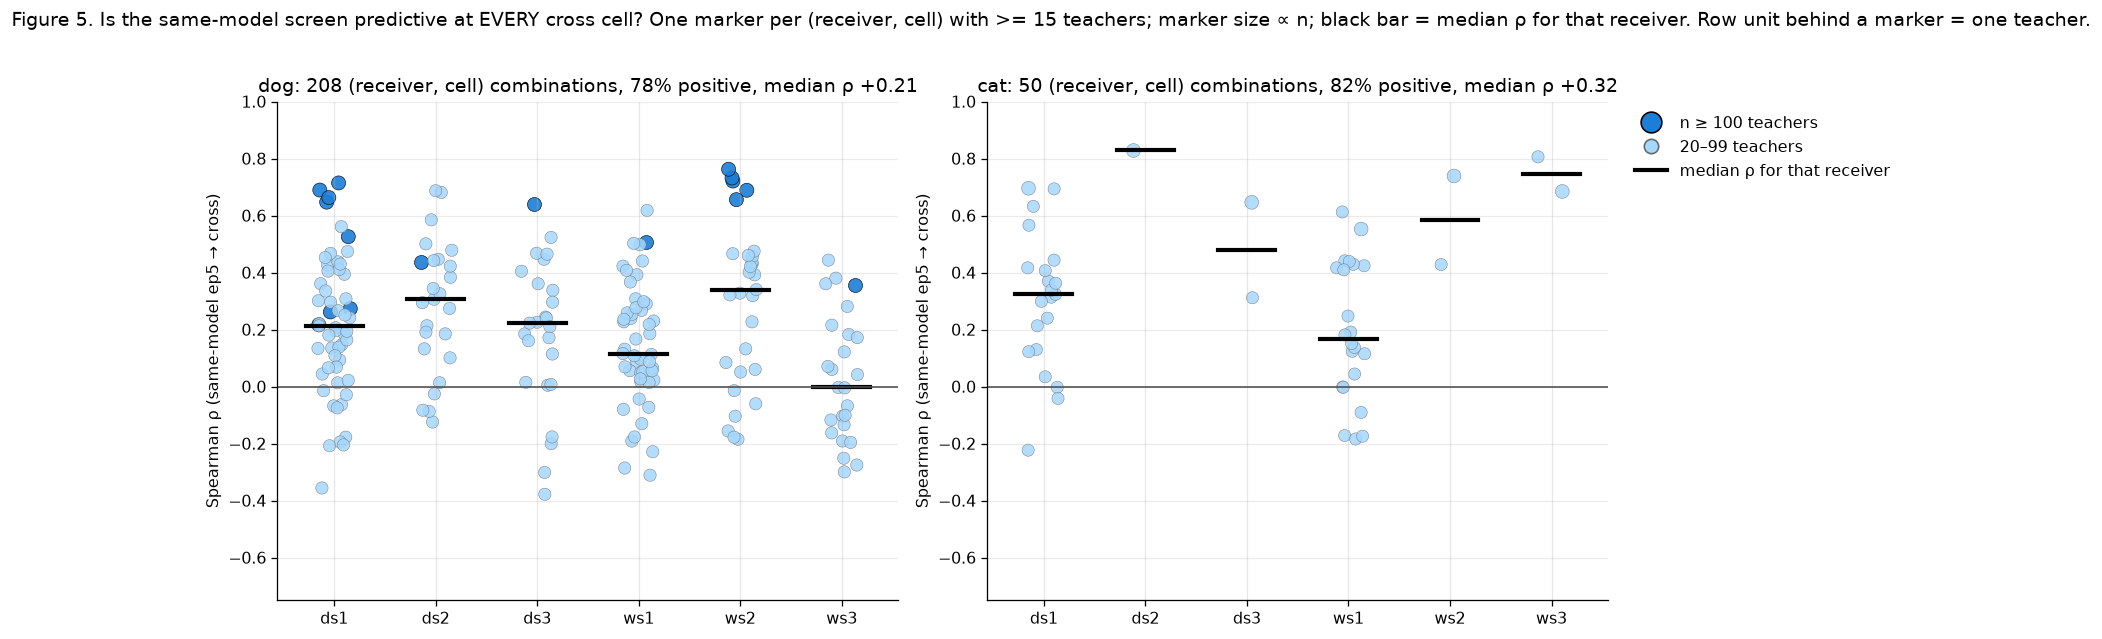

dog: ρ positive at 162/208 combinations, significant (p<0.05) at 38, range -0.38 to +0.76, median +0.21; at the well-powered cells (n >= 100) ρ = +0.71, +0.65, +0.53, +0.22, +0.26, +0.27, +0.69, +0.66, +0.44, +0.64, +0.51, +0.72, +0.69, +0.66, +0.73, +0.76, +0.35.
cat: ρ positive at 41/50 combinations, significant (p<0.05) at 11, range -0.22 to +0.83, median +0.32; at the well-powered cells (n >= 100) none.
Inside the canonical ten (n = 10 teachers) the same ρ has median +0.17 for dog and is significant at 11/208 combinations — range restriction, not absence of signal.


In [16]:
def rho_strip(ax, tbl, title):
    recvs = [r for r in CROSS_RECEIVERS if r in set(tbl.receiver)]
    rng = np.random.default_rng(0)
    for i, recv in enumerate(recvs):
        d = tbl[tbl.receiver == recv]
        x = i + rng.uniform(-0.16, 0.16, len(d))
        big = d.n >= 100
        ax.scatter(x[big.values], d.rho[big], s=3.2 * np.sqrt(d.n[big]) + 45, color="#1c7ed6",
                   edgecolor="k", lw=.4, alpha=.9)
        ax.scatter(x[~big.values], d.rho[~big], s=3.2 * np.sqrt(d.n[~big]) + 45, color="#a5d8ff",
                   edgecolor="0.4", lw=.3, alpha=.85,
                   label="20–99 teachers" if i == 0 else None)
        ax.plot([i - 0.28, i + 0.28], [d.rho.median()] * 2, color="k", lw=2.6)
    ax.axhline(0, color="0.3", lw=1)
    ax.set(xticks=range(len(recvs)), ylim=(-0.75, 1.0), ylabel="Spearman ρ (same-model ep5 → cross)",
           title=title)
    ax.set_xticklabels(recvs)
    ax.grid(axis="y", alpha=.25)


tbls = [("dog", DOG_CROSS_TBL), ("cat", CAT_CROSS_TBL)]
tbls = [(a, t) for a, t in tbls if len(t)]
fig, axes = plt.subplots(1, len(tbls), figsize=(7.5 * len(tbls), 5.4), squeeze=False)
for ax, (a, t) in zip(axes[0], tbls):
    rho_strip(ax, t, f"{a}: {len(t)} (receiver, cell) combinations, "
                     f"{100 * (t.rho > 0).mean():.0f}% positive, median ρ {t.rho.median():+.2f}")
from matplotlib.lines import Line2D  # legend proxies: real markers are sized by n
proxies = [Line2D([], [], marker="o", ls="", ms=13, color="#1c7ed6", mec="k", label="n ≥ 100 teachers"),
           Line2D([], [], marker="o", ls="", ms=9, color="#a5d8ff", mec="0.4", label="20–99 teachers"),
           Line2D([], [], color="k", lw=2.6, label="median ρ for that receiver")]
axes[0][-1].legend(handles=proxies, loc="upper left", bbox_to_anchor=(1.02, 1), frameon=False,
                   fontsize=10)  # house right-margin legend
fig.suptitle(f"Figure 5. Is the same-model screen predictive at EVERY cross cell? One marker per "
             f"(receiver, cell) with >= {MIN_CELL_N} teachers; marker size ∝ n; black bar = median "
             "ρ for that receiver. Row unit behind a marker = one teacher.", y=1.02)
plt.tight_layout(); plt.show()
for a, t in tbls:
    print(f"{a}: ρ positive at {int((t.rho > 0).sum())}/{len(t)} combinations, significant "
          f"(p<0.05) at {int((t.p < 0.05).sum())}, range {t.rho.min():+.2f} to {t.rho.max():+.2f}, "
          f"median {t.rho.median():+.2f}; at the well-powered cells (n >= 100) "
          f"{'ρ = ' + ', '.join(f'{v:+.2f}' for v in t[t.n >= 100].rho) if (t.n >= 100).any() else 'none'}.")
print(f"Inside the canonical ten (n = 10 teachers) the same ρ has median "
      f"{DOG_CROSS_TBL.rho_top10.median():+.2f} for dog and is significant at "
      f"{int((DOG_CROSS_TBL.p_top10 < 0.05).sum())}/{len(DOG_CROSS_TBL)} combinations — range "
      "restriction, not absence of signal.")

**Reading 2c.** Over a wide teacher set the same-model screen is a *moderate but consistent*
predictor of cross transfer into shared-init receivers: in Figure 6 every receiver's bar is
positive at the fixed cell, and Figure 7 shows the same sign at essentially every other
(receiver, cell) combination with enough teachers, with no systematic dependence on the cell's
dose. The middle row of Figure 6 says what those correlations order: the canonical ten average
well above the median teacher of each receiver but only a fraction of the best single teacher for
it — "good, not best", the same picture §2a gave. Inside the ten the correlation collapses (light
bars, p > 0.05): they span too narrow a slice of the predictor to be ordered by it, which is why
an earlier check restricted to the ten found nothing. None of this can be extended to the `fs`
receivers, which have only ever been given the ten — the gap the Stage-2 audit fills.

### 2d. …and how much of that is just the teacher's own trait expression?

**Question (Angela, 2026-09-15).** *What is the correlation between same-model transfer and
cross-model transfer after fixing teacher p(trait)? Similarly, check the teacher's Pile ΔCE.*
§2c showed the same-model screen predicts cross transfer. But a teacher that expresses the trait
strongly distils it into *any* student, so the §2c correlation could be nothing more than
"expressed trait predicts both sides". §2d removes the teacher's expressed trait from both
variables and asks what is left.

**Row unit:** one `orig` (`pythia-160m`, ftseed1) teacher. **Selection:** every orig teacher that
has (a) a same-model ep5 standard-cell student
(`students/{animal}/pythia-160m/teacher-pythia-160m/{tag}_tseed1/ex10-20_prefix_n*k/ep5_lr1e-4_r8a32/ftseed1`,
n100k preferred when both pool sizes exist — the §2a `screen` frame), (b) a teacher preference eval
(`teachers/{animal}/pythia-160m/{tag}/ftseed1/preference_eval.json` → `sets.validation.p_target`,
`sets.off_topic.p_target`) and (c) a teacher Pile probe (`…/eval/pile_probe.json` → `delta_ce`) —
i.e. the §1 `census` joined to the §2a screen. No containment gate is applied: the point is to
span the trait-expression axis.

**Predictors** (per teacher): same-model score = log₁₀ test transfer of its ep5 std same-model
student; teacher validation p(animal) and off-topic p(animal), both in logit units; teacher Pile
ΔCE (nats). **Outcome:** log₁₀ cross transfer of the *same* teacher into each receiver
ds1/ds2/ds3/ws1/ws2/ws3 at **one fixed cell** — dog `ep20_lr1e-4_r8a32`, cat `ep5_lr1e-4_r8a32`
(the §2c headline cells; cat's cross runs sit under `ex10-20_prefix_n40k`). Table 2d-3 swaps the
outcome for the same-model score itself.

**Statistic.** Plain Spearman ρ, and the **rank-partial Spearman**

$$\rho_{xy\mid Z}=\mathrm{corr}\!\left(r_x-\hat r_x(Z),\; r_y-\hat r_y(Z)\right),\qquad
r_\bullet=\mathrm{rank}(\bullet),\quad \hat r_\bullet(Z)=\text{OLS fit of } r_\bullet \text{ on }
[\mathbf 1,\,\mathrm{rank}(Z)],$$

with the Pearson p-value of the two residual vectors. Two covariate sets: **(i) validation p**
alone and **(ii) validation + off-topic p**. Off-topic p is in because validation p is *saturated*
— 59 % of dog and 69 % of cat teachers sit above 0.99 (Table 2d-1), so ranking on it is mostly
ranking noise — while off-topic p measures the same expressed trait on prompts that never mention
animals and is not at its ceiling. Controlling on both is therefore the sharper test of "fix the
teacher's trait expression"; see the caveat in Reading 2d.

**Column legend.** `n` = teachers in that (animal, receiver) row. `ρ(same-model, cross)` = the §2c
correlation recomputed on this row's set. `same-model | val`, `same-model | val+off` = the same
correlation with covariate set (i), (ii) removed. `ρ(ΔCE, cross)`, `ΔCE | val`, `ΔCE | val+off` =
the same three for the teacher's Pile ΔCE. `ρ(val, cross)`, `ρ(off-topic, cross)` = how well the
two trait-expression readouts predict cross transfer on their own. Every entry is `ρ (p)`.

In [17]:
# ---- rank-partial Spearman ---------------------------------------------------------------
# rho_partial(x, y | Z) = Pearson of the residuals of rank(x) and rank(y) after least-squares
# regression on [1, rank(Z)]. Reduces to plain Spearman when Z is empty.
def _rank(v):
    return stats.rankdata(np.asarray(v, dtype=float))


def rho_partial(x, y, covs=()):
    """(rho, p, n) of rank-partial Spearman; covs = sequence of covariate arrays."""
    cols = [np.asarray(c, dtype=float) for c in covs]
    M = np.column_stack([np.asarray(x, float), np.asarray(y, float)] + cols)
    M = M[np.isfinite(M).all(axis=1)]
    n = len(M)
    if n < len(cols) + 4:
        return np.nan, np.nan, n
    rx, ry = _rank(M[:, 0]), _rank(M[:, 1])
    if not cols:
        r = stats.pearsonr(rx, ry)
        return r.statistic, r.pvalue, n
    Z = np.column_stack([np.ones(n)] + [_rank(M[:, 2 + i]) for i in range(len(cols))])
    ex = rx - Z @ np.linalg.lstsq(Z, rx, rcond=None)[0]
    ey = ry - Z @ np.linalg.lstsq(Z, ry, rcond=None)[0]
    r = stats.pearsonr(ex, ey)
    return r.statistic, r.pvalue, n


def rp(x, y, covs=()):
    """'rho (p)' cell text."""
    r, p, _ = rho_partial(x, y, covs)
    return "—" if not np.isfinite(r) else f"{r:+.2f} ({p:.1g})"


def logit(p):
    q = np.clip(np.asarray(p, dtype=float), 1e-6, 1 - 1e-6)
    return np.log(q / (1 - q))


# ---- one row per orig teacher: predictors -------------------------------------------------
CROSS_CELL_2D = {"dog": DOG_CROSS_CELL, "cat": LADDER_CELL}
CROSS_RUNS_2D = {"dog": DOG_CROSS_RUNS, "cat": CAT_CROSS_RUNS}


def teacher_predictors(animal: str) -> pd.DataFrame:
    """orig teachers with an ep5 std same-model student AND a teacher eval AND a Pile probe.

    Read straight off the teacher tree rather than through the §1 `census`: the screened set holds
    a few tags outside grid288 (dog keeps two `lr1e-5` teachers) and they belong here, since §2d
    wants the widest possible span of the trait-expression axis.
    """
    sm = same_model_score(animal, LADDER_CELL).rename("same_model").dropna()
    tags = list(sm.index)
    pref = load_preference_evals(
        OUTPUT_ROOT, [f"teachers/{animal}/pythia-160m/{t}/ftseed1" for t in tags])
    probe = load_run_docs(
        OUTPUT_ROOT, [f"teachers/{animal}/pythia-160m/{t}/ftseed1" for t in tags],
        "eval/pile_probe.json", "teacher_pile_probe")

    def pset(tag, name):
        doc = pref.get(f"teachers/{animal}/pythia-160m/{tag}/ftseed1") or {}
        return ((doc.get("sets") or {}).get(name) or {}).get("p_target", np.nan)

    d = pd.DataFrame({
        "val_p": [pset(t, "validation") for t in tags],
        "off_topic_p": [pset(t, "off_topic") for t in tags],
        "delta_ce": [(probe.get(f"teachers/{animal}/pythia-160m/{t}/ftseed1")
                      or {}).get("delta_ce", np.nan) for t in tags],
    }, index=pd.Index(tags, name="param_tag"))
    d = d.join(sm, how="inner").dropna(subset=["val_p", "off_topic_p", "delta_ce", "same_model"])
    d["log_same_model"] = np.log10(d.same_model.clip(lower=1e-3))
    d["val_logit"], d["off_logit"] = logit(d.val_p), logit(d.off_topic_p)
    return d


PRED_2D = {a: teacher_predictors(a) for a in ("dog", "cat")}
COV1 = ["val_logit"]                 # (i)  fix the teacher's validation p(animal)
COV2 = ["val_logit", "off_logit"]    # (ii) + its off-topic p(animal)

# Table 1 -- are the four predictors one axis?
rows = []
for a, d in PRED_2D.items():
    pairs = [("same-model", "log_same_model"), ("val p", "val_logit"),
             ("off-topic p", "off_logit"), ("ΔCE", "delta_ce")]
    r = {"animal": a, "n teachers": len(d)}
    for (la, ca), (lb, cb) in combinations(pairs, 2):
        r[f"ρ({la}, {lb})"] = stats.spearmanr(d[ca], d[cb]).correlation
    r["val p > 0.99"] = d.val_p.gt(0.99).mean()
    r["val p median"] = d.val_p.median()
    r["ΔCE min"], r["ΔCE max"] = d.delta_ce.min(), d.delta_ce.max()
    rows.append(r)
tbl_2d_1 = pd.DataFrame(rows)
sty(tbl_2d_1, "Table 2d-1 — predictor collinearity. Row unit: one animal's orig teacher set "
    "(ftseed1) with an ep5 std same-model student, a teacher eval and a Pile probe. Spearman ρ "
    "over teachers among the four predictors (p in logit units; ρ is rank-based so the transform "
    "is cosmetic), plus the saturation of validation p and the ΔCE span.",
    div=[c for c in tbl_2d_1.columns if c.startswith("ρ(")],
    fmts={"val p > 0.99": "{:.0%}", "val p median": "{:.4f}"}, hide_index=True)

# Table 2 -- same-model -> cross and ΔCE -> cross, raw and partial
rows = []
for a, d in PRED_2D.items():
    cell, runs = CROSS_CELL_2D[a], CROSS_RUNS_2D[a]
    for recv in CROSS_RECEIVERS:
        cr = runs.get((recv, cell))
        if cr is None or cr.empty:
            continue
        j = d.join(cr.set_index("teacher")[["log10_cross"]], how="inner").dropna()
        if len(j) < MIN_CELL_N:
            continue
        y, cov1 = j.log10_cross, [j[c] for c in COV1]
        cov2 = [j[c] for c in COV2]
        rows.append({
            "animal": a, "receiver": recv, "cell": cell, "n": len(j),
            "ρ(same-model, cross)": rp(j.log_same_model, y),
            "same-model | val": rp(j.log_same_model, y, cov1),
            "same-model | val+off": rp(j.log_same_model, y, cov2),
            "ρ(ΔCE, cross)": rp(j.delta_ce, y),
            "ΔCE | val": rp(j.delta_ce, y, cov1),
            "ΔCE | val+off": rp(j.delta_ce, y, cov2),
            "ρ(val, cross)": rp(j.val_logit, y),
            "ρ(off-topic, cross)": rp(j.off_logit, y),
        })
tbl_2d_2 = pd.DataFrame(rows)
display(tbl_2d_2.style.set_caption(
    "Table 2d-2 — does same-model transfer predict cross transfer once the teacher's expressed "
    "trait is fixed? Row unit: one (animal, receiver) at ONE cell — dog ep20_lr1e-4_r8a32, cat "
    "ep5_lr1e-4_r8a32 — over the orig teachers of Table 2d-1 that also have that cross run. Each "
    "entry is 'ρ (p)': plain Spearman for the ρ(·) columns, rank-partial Spearman controlling for "
    "validation p ('| val') or validation + off-topic p ('| val+off')."
).hide(axis="index"))

# Table 3 -- ΔCE against the SAME-model outcome
rows = []
for a, d in PRED_2D.items():
    y = d.log_same_model
    rows.append({"animal": a, "n": len(d), "cell": LADDER_CELL,
                 "ρ(ΔCE, same-model)": rp(d.delta_ce, y),
                 "ΔCE | val": rp(d.delta_ce, y, [d[c] for c in COV1]),
                 "ΔCE | val+off": rp(d.delta_ce, y, [d[c] for c in COV2])})
tbl_2d_3 = pd.DataFrame(rows)
display(tbl_2d_3.style.set_caption(
    "Table 2d-3 — the same control applied to the SAME-model outcome. Row unit: one animal's orig "
    "teacher set; outcome = log10 same-model transfer at ep5_lr1e-4_r8a32; entries 'ρ (p)'."
).hide(axis="index"))

animal,n teachers,"ρ(same-model, val p)","ρ(same-model, off-topic p)","ρ(same-model, ΔCE)","ρ(val p, off-topic p)","ρ(val p, ΔCE)","ρ(off-topic p, ΔCE)",val p > 0.99,val p median,ΔCE min,ΔCE max
dog,102,0.941,0.966,0.952,0.979,0.906,0.957,59%,0.9967,0.0261,2.76
cat,84,0.895,0.957,0.928,0.934,0.835,0.953,69%,0.9984,0.0571,2.52


animal,receiver,cell,n,"ρ(same-model, cross)",same-model | val,same-model | val+off,"ρ(ΔCE, cross)",ΔCE | val,ΔCE | val+off,"ρ(val, cross)","ρ(off-topic, cross)"
dog,ds1,ep20_lr1e-4_r8a32,102,+0.53 (1e-08),+0.23 (0.02),+0.19 (0.06),+0.48 (4e-07),+0.10 (0.3),-0.01 (0.9),+0.49 (2e-07),+0.50 (8e-08)
dog,ds2,ep20_lr1e-4_r8a32,102,+0.44 (4e-06),+0.31 (0.002),+0.27 (0.006),+0.41 (2e-05),+0.22 (0.03),+0.15 (0.1),+0.36 (0.0002),+0.39 (6e-05)
dog,ds3,ep20_lr1e-4_r8a32,102,+0.64 (5e-13),+0.26 (0.007),+0.09 (0.4),+0.67 (2e-14),+0.35 (0.0003),+0.18 (0.07),+0.60 (2e-11),+0.64 (4e-13)
dog,ws1,ep20_lr1e-4_r8a32,102,+0.51 (5e-08),+0.11 (0.3),+0.07 (0.5),+0.52 (3e-08),+0.16 (0.1),+0.15 (0.1),+0.51 (6e-08),+0.51 (4e-08)
dog,ws2,ep20_lr1e-4_r8a32,101,+0.66 (1e-13),+0.16 (0.1),+0.06 (0.6),+0.66 (8e-14),+0.20 (0.04),+0.11 (0.3),+0.65 (1e-13),+0.67 (2e-14)
dog,ws3,ep20_lr1e-4_r8a32,102,+0.35 (0.0003),+0.12 (0.2),+0.09 (0.4),+0.31 (0.002),+0.01 (0.9),-0.10 (0.3),+0.34 (0.0006),+0.35 (0.0004)
cat,ds1,ep5_lr1e-4_r8a32,84,+0.70 (2e-13),+0.27 (0.01),+0.14 (0.2),+0.66 (1e-11),+0.22 (0.04),+0.02 (0.9),+0.68 (2e-12),+0.70 (2e-13)
cat,ds2,ep5_lr1e-4_r8a32,84,+0.83 (2e-22),+0.54 (1e-07),+0.18 (0.09),+0.82 (2e-21),+0.53 (2e-07),+0.04 (0.7),+0.75 (3e-16),+0.84 (3e-23)
cat,ds3,ep5_lr1e-4_r8a32,84,+0.65 (3e-11),+0.37 (0.0005),+0.04 (0.7),+0.73 (2e-15),+0.57 (2e-08),+0.38 (0.0004),+0.57 (2e-08),+0.67 (4e-12)
cat,ws1,ep5_lr1e-4_r8a32,84,+0.55 (5e-08),+0.18 (0.1),+0.06 (0.6),+0.54 (2e-07),+0.18 (0.1),+0.03 (0.8),+0.54 (1e-07),+0.56 (2e-08)


animal,n,cell,"ρ(ΔCE, same-model)",ΔCE | val,ΔCE | val+off
dog,102,ep5_lr1e-4_r8a32,+0.95 (5e-53),+0.69 (1e-15),+0.38 (9e-05)
cat,84,ep5_lr1e-4_r8a32,+0.93 (7e-37),+0.74 (2e-15),+0.22 (0.04)


**Reading 2d.** The four predictors are one axis, not four: over the orig teachers the same-model
score, validation p, off-topic p and ΔCE correlate at ρ = 0.84–0.98 (Table 2d-1). Removing the
teacher's expressed trait from both sides accordingly guts the §2c effect. Fixing validation p cuts
ρ(same-model, cross) from +0.35…+0.83 down to +0.11…+0.54; fixing validation **and** off-topic p
leaves +0.04…+0.27, and of the twelve (animal, receiver) rows only dog ds2 stays significant
(Table 2d-2). ΔCE behaves identically against the cross outcome — raw +0.31…+0.82, ≈0 once both
readouts are fixed, with cat ds3 (+0.38) the one exception.

The **same-model** outcome is different: ΔCE keeps a residual effect on same-model transfer
(ρ +0.95/+0.93 raw; | val +0.69/+0.74; | val+off +0.38 at p = 9e-5 for dog and +0.22 at p = 0.04
for cat — both significant, Table 2d-3). So the teacher's Pile damage carries information about
same-model distillation beyond what its trait probes say, but nothing extra about cross-model
distillation.

The conclusion for the audit: §2c's "the same-model screen predicts cross transfer" is mostly
"teacher trait expression predicts both". **Beyond the expressed trait there is no cross-model
signal at one seed and one cell** — which is why picking teachers by same-model rank buys little
over picking them by their own p(animal). **Caveat:** off-topic p is plausibly a *mediator* rather
than a confounder (the trait leaking into off-topic prompts is much the same thing as the numbers
carrying the trait), so the `| val+off` column may over-control; the `| val` column is the
conservative read, and it already shows the effect roughly halving.

## 4. Per-animal teacher ranking by distill performance

Angela's question: *for each animal, rank the teachers by how well they distil.* Row unit of the
underlying data: one student run at `ep5_lr1e-4_r8a32`, ftseed1, single seed, same-model, taken
from the Stage-2 audit's expected-run paths — the historical orig/ds1 screens (adopted as the
audit's orig/ds1 arm by design, with only `off_topic` and the pile probe to backfill) plus
whatever the campaign has landed on fs1/fs2/fs3. Score = transfer = test $p(\text{animal})$ /
that base's prior; a teacher's **rank within a base** is computed only among that base's landed
runs, and `mean_rank` averages the ranks a teacher actually has. Cat is the primary subject
(`PRIMARY_ANIMAL`), then dog, lion, pig; coverage and pool-check skips are the two printed
sentences below.

In [18]:
def audit_spec(a, s):
    pool_f = AUDIT_DIR / f"{a}_{s}_pool_tags.json"
    cand_f = AUDIT_DIR / f"{a}_{s}_candidates.json"
    if pool_f.exists():
        return read_json(pool_f), "pool_tags"
    if cand_f.exists():
        return read_json(cand_f), "candidates"
    return None, "missing"


audit_rows, smoke_rows, audit_cov = [], [], []
AUDIT_SPECS: dict[tuple[str, str], dict] = {}
for a in ANIMALS:
    for s in BASES:
        spec, src = audit_spec(a, s)
        if spec is not None:
            AUDIT_SPECS[(a, s)] = spec
        if spec is None:
            audit_cov.append({"animal": a, "base": s, "source": src, "n_expected": 0,
                              "n_landed": 0, "n_probed": 0})
            continue
        d = BASES[s]["dir"]
        tree = OUTPUT_ROOT / "students" / a / d / f"teacher-{d}"
        tags = list(spec["param_tags"])
        for tag, blk in (spec.get("smoke") or {}).items():
            smoke_rows.append({"animal": a, "base": s, "tag": tag, "is_top10": tag in TOP10,
                               "kept": tag in set(tags), **blk})
        rels = {}
        for tag in tags:
            ds = discover_dataset(tree, tag) if (tree / f"{tag}_tseed1").exists() else None
            ds = ds or "ex10-20_prefix_n100k"
            rels[tag] = f"students/{a}/{d}/teacher-{d}/{tag}_tseed1/{ds}/{LADDER_CELL}/ftseed1"
        pref = load_preference_evals(OUTPUT_ROOT, list(rels.values()))
        probe = load_run_docs(OUTPUT_ROOT, list(rels.values()), "eval/pile_probe.json",
                              "audit_pile_probe")
        n_probed = n_offtopic = 0
        for tag, rel in rels.items():
            doc = pref.get(rel)
            if doc is None:
                continue
            sets_ = doc.get("sets") or {}
            pr = probe.get(rel) or {}
            n_probed += bool(pr)
            n_offtopic += (sets_.get("off_topic") or {}).get("p_target") is not None
            audit_rows.append({
                "animal": a, "base": s, "teacher": tag, "is_top10": tag in TOP10,
                "test": (sets_.get("test") or {}).get("p_target", np.nan),
                "off_topic": (sets_.get("off_topic") or {}).get("p_target", np.nan),
                "kl": pr.get("kl_base_student", pr.get("kl", np.nan)),
                "delta_ce_student": pr.get("delta_ce", np.nan),
                "base_dir": d, "anchored_cut": ANCHORED[d]})
        n_landed = sum(r in pref for r in rels.values())
        audit_cov.append({"animal": a, "base": s, "source": src, "n_expected": len(tags),
                          "n_landed": n_landed, "n_off_topic_scored": n_offtopic,
                          "n_probed": n_probed,
                          "backfill_off_topic_todo": n_landed - n_offtopic,
                          "backfill_probe_todo": n_landed - n_probed})
audit = pd.DataFrame(audit_rows)
if len(audit):
    audit["prior"] = [PRIORS[(a, s)] for a, s in zip(audit.animal, audit.base)]
    audit["transfer"] = audit.test / audit.prior
    # operative label: the receiver's unigram-anchored Pile-KL cut (per base)
    audit["dead"] = labels.label_dead_kl(audit, ANCHORED, base_col="base_dir")
cov4 = pd.DataFrame(audit_cov)
print(f"Stage-2 coverage (no table), expected = spec tags x {LADDER_CELL} at ftseed1: "
      f"{int(cov4.n_expected.sum())} expected runs over {len(cov4)} trees from "
      + "/".join(sorted(cov4.source.unique())) + " specs; "
      f"{int(cov4.n_landed.sum())} landed "
      f"({', '.join(f'{b} {int(v)}' for b, v in cov4.groupby('base').n_landed.sum().items())}). "
      f"Backfill still owed: off_topic on {int(cov4.backfill_off_topic_todo.sum())} landed runs, "
      f"a student pile probe on {int(cov4.backfill_probe_todo.sum())}. Trees with nothing landed: "
      + ", ".join(f"{r.animal}|{r.base}" for r in cov4[cov4.n_landed == 0].itertuples()) + ".")

Stage-2 coverage (no table), expected = spec tags x ep5_lr1e-4_r8a32 at ftseed1: 1434 expected runs over 20 trees from pool_tags specs; 841 landed (ds1 296, fs1 276, fs2 0, fs3 0, orig 269). Backfill still owed: off_topic on 269 landed runs, a student pile probe on 0. Trees with nothing landed: dog|fs2, dog|fs3, cat|fs2, cat|fs3, lion|fs2, lion|fs3, pig|fs2, pig|fs3.


In [19]:
smoke = pd.DataFrame(smoke_rows)
if smoke.empty:
    print("Pool check (no table): no *_pool_tags.json spec has a smoke block yet.")
else:
    skipped = smoke[~smoke.kept]
    counts = ", ".join(f"{k} {v}" for k, v in smoke.status.value_counts().items())
    print(f"Pool check (no table): {len(smoke)} candidate tags screened ({counts}); "
          f"{len(skipped)} dropped, {int(skipped.is_top10.sum())} of them canonical"
          + ("." if skipped.empty else ": " + "; ".join(
              f"{r.animal}|{r.base} {r.tag} (keep rate {r.keep_rate:.2f}, projected "
              f"{r.projected_n_filtered:,.0f} filtered)" for r in skipped.itertuples())
             + ". These stay visible as unranked rows below."))

Pool check (no table): 1437 candidate tags screened (pass 747, real-pool 687, skip 3); 3 dropped, 0 of them canonical: dog|orig ep15_lr2e-4_r16a16 (keep rate 0.09, projected nan filtered); cat|orig ep15_lr2e-4_r16a16 (keep rate 0.19, projected 19,000 filtered); cat|orig ep20_lr1e-4_r8a32 (keep rate 0.23, projected 22,567 filtered). These stay visible as unranked rows below.


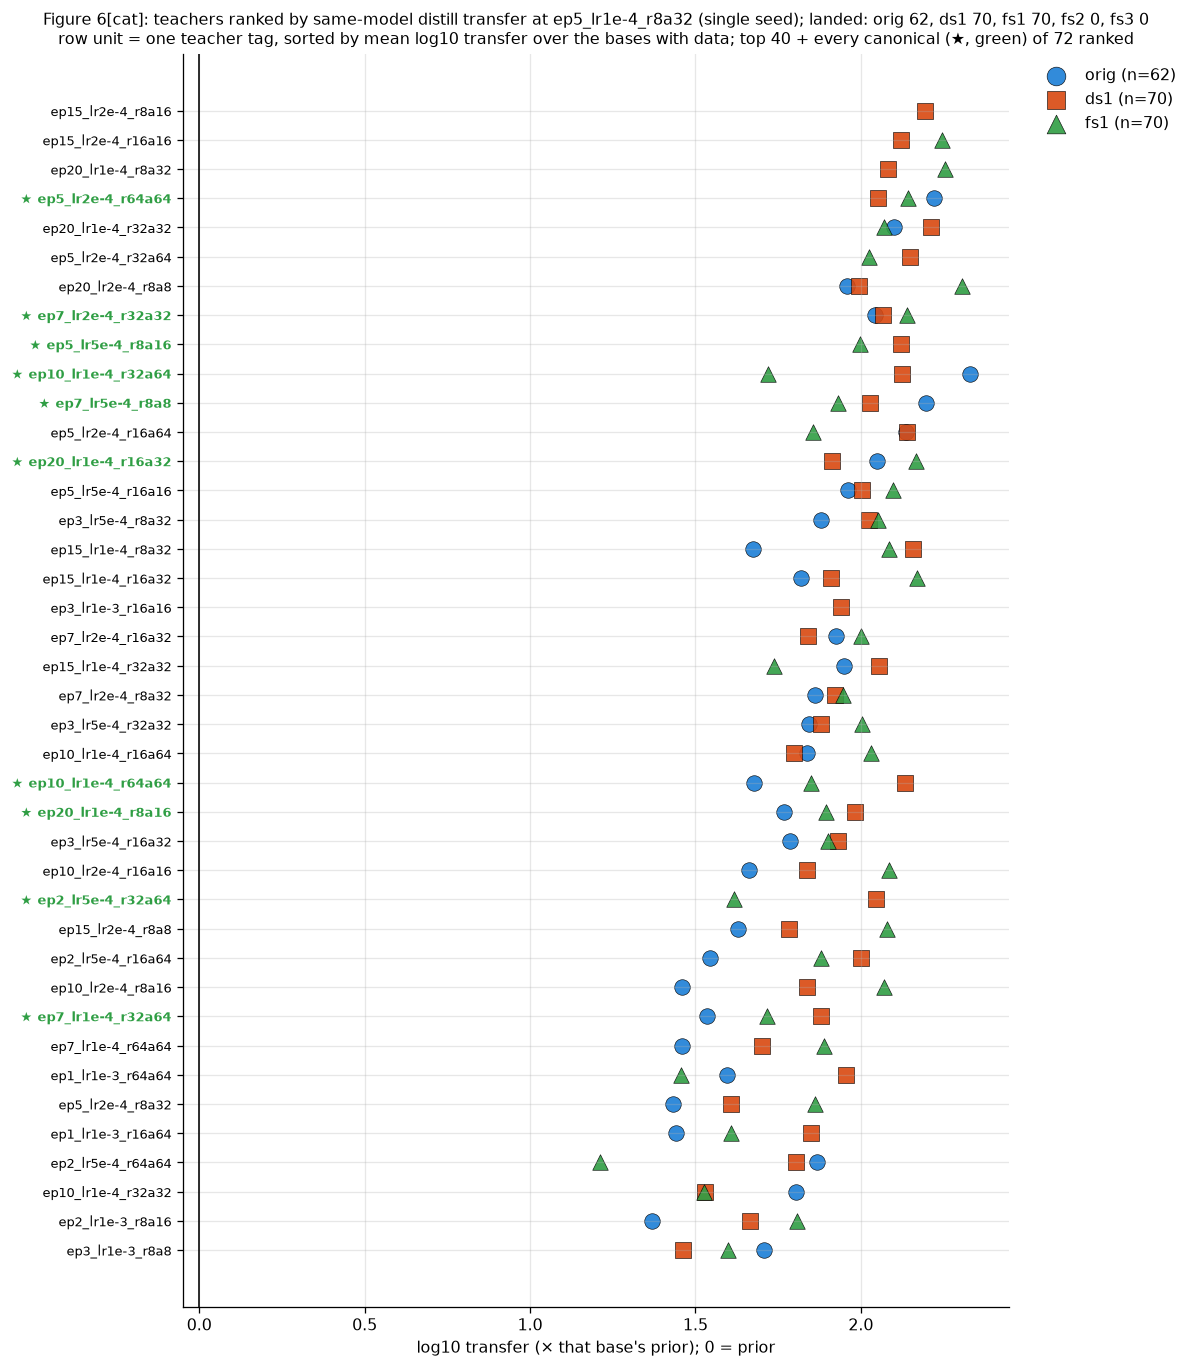

base,transfer on orig (× prior),transfer on ds1 (× prior),transfer on fs1 (× prior),rank on orig (of 62),rank on ds1 (of 70),rank on fs1 (of 70),mean rank,overall position,teacher ΔCE (nats)
teacher,,,,,,,,,
ep5_lr2e-4_r64a64,166.5,112.7,138.5,2,13,6,7.0,5,1.90
ep7_lr2e-4_r32a32,110.5,117.0,137.5,7,11,7,8.3,6,1.12
ep20_lr1e-4_r16a32,111.9,81.9,146.4,6,25,5,12.0,10,1.83
ep7_lr5e-4_r8a8,157.5,106.2,85.1,3,15,22,13.3,13,1.85
ep5_lr5e-4_r8a16,—,132.1,99.3,—,9,20,14.5,15,2.32
ep10_lr1e-4_r32a64,213.2,133.6,52.3,1,7,37,15.0,16,1.50
ep10_lr1e-4_r64a64,47.6,136.3,70.7,23,6,31,20.0,20,1.29
ep20_lr1e-4_r8a16,58.6,95.8,78.6,20,20,25,21.7,23,0.48
ep2_lr5e-4_r32a64,—,111.4,41.4,—,14,43,28.5,31,1.73


  per-cat top-10 pick (10 best by mean log10 transfer, runs on >= 2 bases; overlap with the canonical ten 5/10): ep15_lr2e-4_r16a16, ep20_lr1e-4_r8a32, ★ep5_lr2e-4_r64a64, ep20_lr1e-4_r32a32, ep5_lr2e-4_r32a64, ep20_lr2e-4_r8a8, ★ep7_lr2e-4_r32a32, ★ep5_lr5e-4_r8a16, ★ep10_lr1e-4_r32a64, ★ep7_lr5e-4_r8a8
  6 candidate tags have no landed run yet.


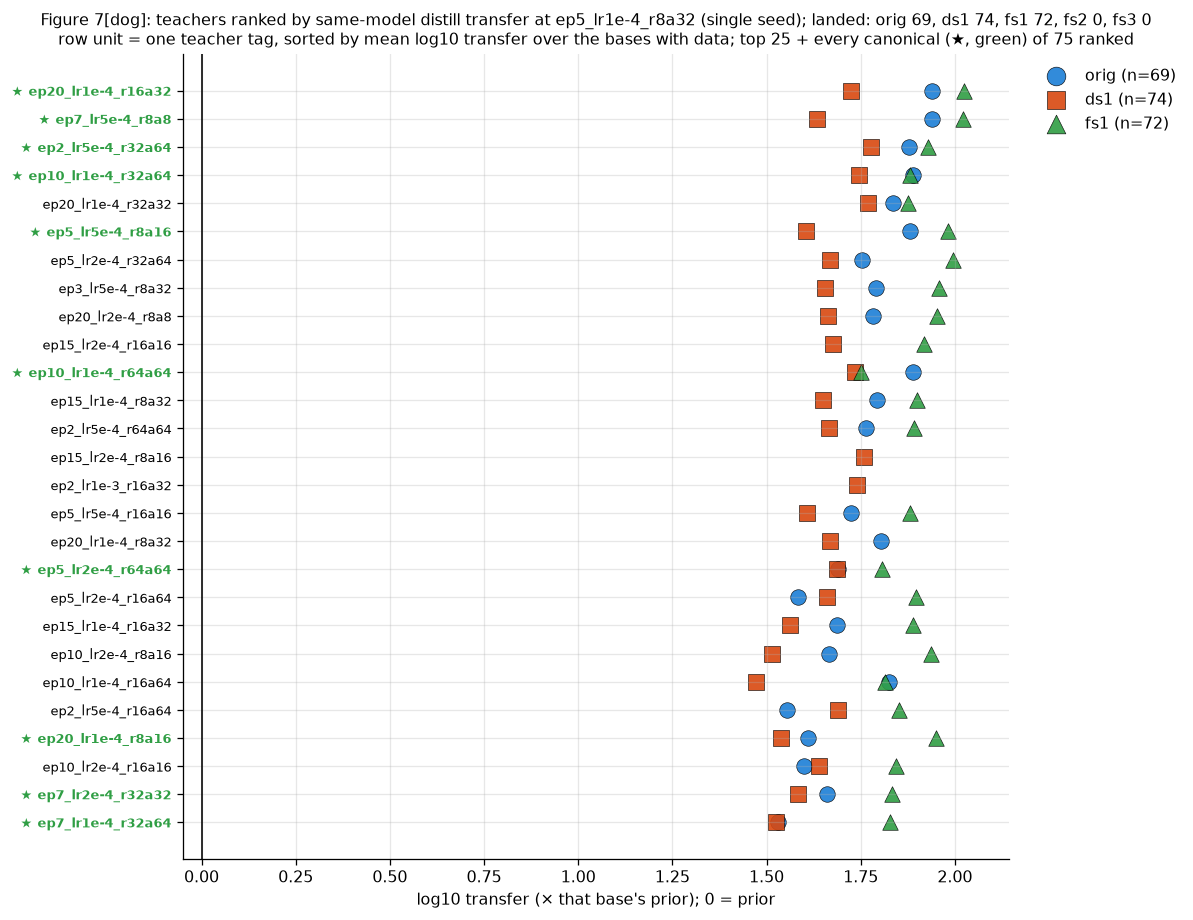

base,transfer on orig (× prior),transfer on ds1 (× prior),transfer on fs1 (× prior),rank on orig (of 69),rank on ds1 (of 74),rank on fs1 (of 72),mean rank,overall position,teacher ΔCE (nats)
teacher,,,,,,,,,
ep20_lr1e-4_r16a32,87.0,52.9,105.8,1,7,1,3.0,1,2.06
ep2_lr5e-4_r32a64,75.5,60.0,84.7,6,1,10,5.7,4,2.20
ep7_lr5e-4_r8a8,86.7,43.1,105.1,2,19,2,7.7,5,2.03
ep10_lr1e-4_r32a64,77.5,55.7,75.9,3,4,18,8.3,6,1.67
ep5_lr5e-4_r8a16,76.0,40.2,96.1,5,24,4,11.0,13,2.54
ep10_lr1e-4_r64a64,77.3,54.2,56.2,4,6,35,15.0,16,1.51
ep5_lr2e-4_r64a64,49.0,48.5,63.9,17,9,31,19.0,20,2.00
ep20_lr1e-4_r8a16,40.6,34.5,89.0,22,33,7,20.7,22,0.58
ep7_lr2e-4_r32a32,45.6,38.3,68.0,21,26,22,23.0,25,1.31


  per-dog top-10 pick (10 best by mean log10 transfer, runs on >= 2 bases; overlap with the canonical ten 5/10): ★ep20_lr1e-4_r16a32, ★ep7_lr5e-4_r8a8, ★ep2_lr5e-4_r32a64, ★ep10_lr1e-4_r32a64, ep20_lr1e-4_r32a32, ★ep5_lr5e-4_r8a16, ep5_lr2e-4_r32a64, ep3_lr5e-4_r8a32, ep20_lr2e-4_r8a8, ep15_lr2e-4_r16a16


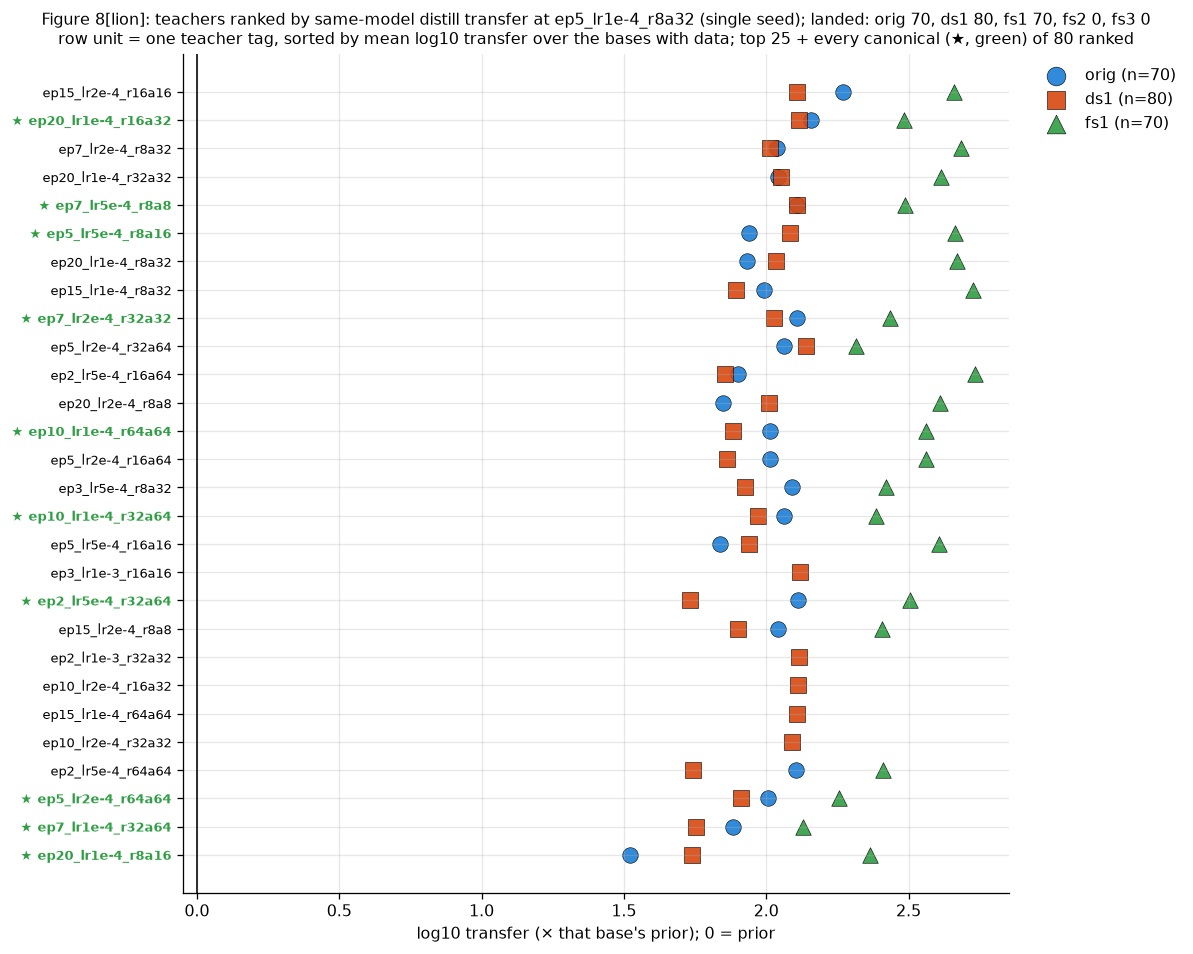

base,transfer on orig (× prior),transfer on ds1 (× prior),transfer on fs1 (× prior),rank on orig (of 70),rank on ds1 (of 80),rank on fs1 (of 70),mean rank,overall position,teacher ΔCE (nats)
teacher,,,,,,,,,
ep20_lr1e-4_r16a32,143.4,130.6,304.1,2,3,16,7.0,5,1.35
ep7_lr5e-4_r8a8,128.2,128.4,307.2,5,7,15,9.0,7,1.63
ep5_lr5e-4_r8a16,86.8,121.5,461.6,21,10,5,12.0,11,2.22
ep7_lr2e-4_r32a32,127.8,106.8,271.6,6,13,18,12.3,12,0.88
ep10_lr1e-4_r32a64,115.9,93.2,242.8,9,18,24,17.0,19,1.22
ep10_lr1e-4_r64a64,103.3,76.7,362.9,15,26,12,17.7,20,1.25
ep2_lr5e-4_r32a64,129.6,54.1,319.3,4,40,14,19.3,25,1.55
ep5_lr2e-4_r64a64,101.3,81.6,180.1,17,21,30,22.7,28,1.63
ep7_lr1e-4_r32a64,76.1,56.8,134.3,25,37,37,33.0,38,0.41


  per-lion top-10 pick (10 best by mean log10 transfer, runs on >= 2 bases; overlap with the canonical ten 4/10): ep15_lr2e-4_r16a16, ★ep20_lr1e-4_r16a32, ep7_lr2e-4_r8a32, ep20_lr1e-4_r32a32, ★ep7_lr5e-4_r8a8, ★ep5_lr5e-4_r8a16, ep20_lr1e-4_r8a32, ep15_lr1e-4_r8a32, ★ep7_lr2e-4_r32a32, ep5_lr2e-4_r32a64
  5 candidate tags have no landed run yet.


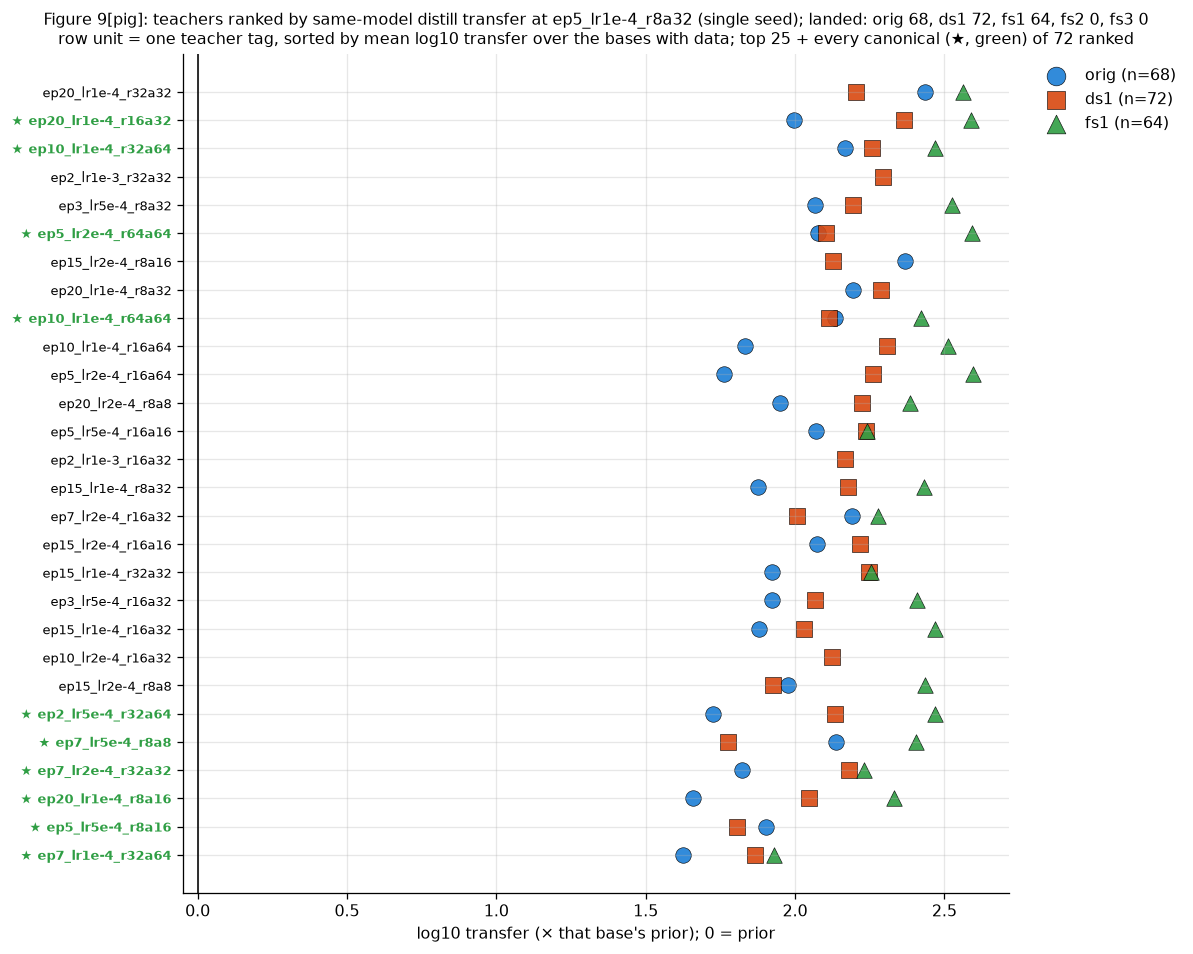

base,transfer on orig (× prior),transfer on ds1 (× prior),transfer on fs1 (× prior),rank on orig (of 68),rank on ds1 (of 72),rank on fs1 (of 64),mean rank,overall position,teacher ΔCE (nats)
teacher,,,,,,,,,
ep20_lr1e-4_r16a32,99.0,231.9,388.3,12,1,3,5.3,3,1.49
ep10_lr1e-4_r32a64,147.4,180.4,294.6,5,7,10,7.3,5,1.29
ep5_lr2e-4_r64a64,119.6,126.7,390.8,8,22,2,10.7,10,1.48
ep10_lr1e-4_r64a64,135.6,130.4,264.0,7,20,15,14.0,12,1.19
ep2_lr5e-4_r32a64,53.2,135.8,294.0,27,17,11,18.3,19,1.61
ep7_lr5e-4_r8a8,137.2,59.7,253.2,6,37,18,20.3,25,1.35
ep7_lr2e-4_r32a32,66.6,152.0,170.5,22,14,28,21.3,26,0.93
ep5_lr5e-4_r8a16,80.1,64.1,—,17,34,—,25.5,30,1.58
ep20_lr1e-4_r8a16,45.7,111.0,214.8,30,28,20,26.0,32,0.38


  per-pig top-10 pick (10 best by mean log10 transfer, runs on >= 2 bases; overlap with the canonical ten 4/10): ep20_lr1e-4_r32a32, ★ep20_lr1e-4_r16a32, ★ep10_lr1e-4_r32a64, ep3_lr5e-4_r8a32, ★ep5_lr2e-4_r64a64, ep15_lr2e-4_r8a16, ep20_lr1e-4_r8a32, ★ep10_lr1e-4_r64a64, ep10_lr1e-4_r16a64, ep5_lr2e-4_r16a64
  2 candidate tags have no landed run yet.


In [20]:
def ranking_frame(a: str) -> pd.DataFrame:
    """Teachers x bases at the ladder cell for one animal (from the §4 audit frame)."""
    if audit.empty:
        return pd.DataFrame()
    d = audit[audit.animal == a].copy()
    if d.empty:
        return pd.DataFrame()
    d["rank_in_base"] = d.groupby("base").transfer.rank(ascending=False, method="min")
    d["log10_transfer"] = np.log10(d.transfer.clip(lower=1e-3))
    wide = d.pivot_table(index="teacher", columns="base", values="transfer")
    ranks = d.pivot_table(index="teacher", columns="base", values="rank_in_base")
    wide = wide.reindex(columns=[b for b in BASES if b in wide.columns])
    ranks = ranks.reindex(columns=wide.columns)
    out = pd.concat([wide.add_prefix("transfer_"), ranks.add_prefix("rank_")], axis=1)
    out["n_bases"] = wide.notna().sum(axis=1)
    out["mean_rank"] = ranks.mean(axis=1)
    out["mean_log_transfer"] = d.groupby("teacher").log10_transfer.mean()
    spec_tags, dropped = set(), {}
    for (an, bs), spec in AUDIT_SPECS.items():
        if an != a:
            continue
        spec_tags |= set(spec["param_tags"])
        for tag, blk in (spec.get("smoke") or {}).items():
            if tag not in set(spec["param_tags"]):
                spec_tags.add(tag)
                dropped.setdefault(tag, []).append(f"{bs}:{blk.get('status', 'skip')}")
    out = out.reindex(sorted(set(out.index) | spec_tags))
    out["dropped_from"] = pd.Series({t: ", ".join(v) for t, v in dropped.items()}).reindex(out.index)
    out["n_bases"] = out.n_bases.fillna(0).astype(int)
    out["is_top10"] = out.index.isin(TOP10)
    cen = census[census.animal == a].groupby("param_tag").delta_ce.median()
    out["teacher_dce_median"] = out.index.map(cen)
    return out.sort_values("mean_log_transfer", ascending=False)


RANKINGS = {a: ranking_frame(a) for a in RANK_ORDER}
FIGNUM = {a: 6 + i for i, a in enumerate(RANK_ORDER)}          # Figures 6-9
BASE_STYLE = {"orig": ("o", "#1c7ed6"), "ds1": ("s", "#d9480f"), "fs1": ("^", "#2f9e44"),
              "fs2": ("v", "#9c36b5"), "fs3": ("D", "#e8590c")}
TOPN = {a: (40 if a == PRIMARY_ANIMAL else 25) for a in RANK_ORDER}

for a in RANK_ORDER:
    r = RANKINGS[a]
    if r.empty:
        print(f"{a}: no ladder-cell runs landed")
        continue
    ranked = r[r.mean_log_transfer.notna()]
    shown = ranked if SHOW_FULL_TABLES else pd.concat(
        [ranked.head(TOPN[a]), ranked[ranked.is_top10]]).pipe(
        lambda d: d[~d.index.duplicated()]).sort_values("mean_log_transfer", ascending=False)
    cnt = audit[audit.animal == a].groupby("base").size().reindex(list(BASES), fill_value=0)
    y = np.arange(len(shown))[::-1]                      # best at the top
    fig, ax = plt.subplots(figsize=(10.5, max(5, 0.30 * len(shown))))
    for b in BASES:
        col = f"transfer_{b}"
        if col not in shown or shown[col].notna().sum() == 0:
            continue
        mk, c = BASE_STYLE[b]
        ax.scatter(np.log10(shown[col]), y, marker=mk, s=95, color=c, edgecolor="k", lw=.4,
                   alpha=.9, label=f"{b} (n={int(cnt[b])})")
    ax.set_yticks(y)
    ax.set_yticklabels([("★ " if t else "") + tag for tag, t in zip(shown.index, shown.is_top10)],
                       fontsize=8)
    for tick, is10 in zip(ax.get_yticklabels(), shown.is_top10):
        if is10:
            tick.set_color("#2f9e44")
            tick.set_fontweight("bold")
    ax.grid(axis="x", alpha=.3)
    vals = np.log10(shown[[c for c in shown.columns if c.startswith("transfer_")]].to_numpy(float))
    lo, hi = np.nanmin(vals), np.nanmax(vals)
    ax.set_xlim(min(lo - 0.12, -0.05), hi + 0.12)   # keep the prior (0) visible, drop dead space
    ax.axvline(0, color="k", lw=1)
    ax.set_xlabel("log10 transfer (× that base's prior); 0 = prior")
    ax.set_title(f"Figure {FIGNUM[a]}[{a}]: teachers ranked by same-model distill transfer at "
                 f"{LADDER_CELL} (single seed); landed: "
                 + ", ".join(f"{b} {int(cnt[b])}" for b in BASES)
                 + (f"\nrow unit = one teacher tag, sorted by mean log10 transfer over the bases "
                    f"with data; top {TOPN[a]} + every canonical (★, green) of "
                    f"{len(ranked)} ranked" if len(shown) < len(ranked) else
                    "\nrow unit = one teacher tag, sorted by mean log10 transfer"), fontsize=10)
    ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), frameon=False, fontsize=10,
              markerscale=1.2)  # house right-margin legend
    plt.tight_layout(); plt.show()

    t10 = r[r.is_top10].copy()
    n_land = {b: int(r[f"rank_{b}"].notna().sum()) for b in BASES if f"rank_{b}" in r}
    t10["overall"] = r.mean_rank.rank(method="min").reindex(t10.index)
    cols, names = [], {}
    for b in BASES:
        if f"transfer_{b}" in r:
            cols.append(f"transfer_{b}"); names[f"transfer_{b}"] = f"transfer on {b} (× prior)"
    for b in BASES:
        if f"rank_{b}" in r:
            cols.append(f"rank_{b}"); names[f"rank_{b}"] = f"rank on {b} (of {n_land[b]})"
    cols += ["mean_rank", "overall", "teacher_dce_median"]
    names |= {"mean_rank": "mean rank", "overall": "overall position",
              "teacher_dce_median": "teacher ΔCE (nats)"}
    tt = t10[cols].rename(columns=names).sort_values(names["mean_rank"])
    sty(tt, f"Table 3[{a}] — the canonical ten only (the single table of §4; the full ranking is "
            f"Figure {FIGNUM[a]}). Row unit = one canonical tag, sorted by mean rank. 'rank on X' "
            "is among that base's landed candidates; 'overall position' is among all "
            f"{int(r.mean_rank.notna().sum())} ranked candidates.",
        seq=[c for c in tt.columns if c.startswith("transfer on")],
        rank=[c for c in tt.columns if c.startswith("rank on")]
             + ["mean rank", "overall position", "teacher ΔCE (nats)"],
        fmts={**{c: "{:.0f}" for c in tt.columns if c.startswith("rank on")},
              "mean rank": "{:.1f}", "overall position": "{:.0f}",
              "teacher ΔCE (nats)": "{:.2f}"}, fmt="{:.1f}")

    pick = ranked[ranked.n_bases >= 2].head(10)
    if len(pick):
        print(f"  per-{a} top-10 pick (10 best by mean log10 transfer, runs on >= 2 bases; "
              f"overlap with the canonical ten {int(pick.index.isin(TOP10).sum())}/10): "
              + ", ".join(("★" if t in TOP10 else "") + t for t in pick.index))
    miss = r[r.mean_log_transfer.isna()]
    if len(miss):
        drop = miss[miss.dropped_from.notna()]
        print(f"  {len(miss)} candidate tags have no landed run yet"
              + ("; dropped by the pool check: "
                 + ", ".join(f"{t} ({d})" for t, d in drop.dropped_from.items())
                 if len(drop) else "") + ".")

### 4c. fs1 — the first full-seed arm with a wide teacher set

Before this audit the fs1 receiver had only ever been given the canonical ten (§2b), so it could
not say whether the ten are *good* fs1 teachers. The `taud-sd-*-fs1-ep5` queues distilled every
gated fs1 candidate into fs1 at `ep5_lr1e-4_r8a32` (ftseed1, single seed, same-model).

**Table 4** — row unit: one animal's fs1 tree. `transfer` = test $p(\text{animal})$ / fs1 prior.
`headroom` = best landed teacher ÷ best canonical teacher. `canonical ranks` = the span of
positions the canonical tags hold among that tree's landed fs1 runs (1 = best). The three ρ columns are
Spearman correlations over teachers of fs1 transfer against (i) the same tag's orig screen transfer,
(ii) its ds1 screen transfer, (iii) the fs1 teacher's own Pile ΔCE (all at the same student cell).

In [21]:
FS = "fs1"
t4 = []
for a in RANK_ORDER:
    d = audit[(audit.animal == a) & (audit.base == FS)].set_index("teacher")
    if d.empty:
        continue
    tr = d.transfer.sort_values(ascending=False)
    pos = pd.Series(np.arange(1, len(tr) + 1), index=tr.index)
    canon = tr[tr.index.isin(TOP10)]
    other = {b: audit[(audit.animal == a) & (audit.base == b)].set_index("teacher").transfer
             for b in ("orig", "ds1")}
    tdce = census[(census.animal == a) & (census.base_short == FS)].set_index("param_tag").delta_ce

    def rho(v):
        m = pd.concat([tr, v], axis=1, join="inner").dropna()
        return stats.spearmanr(m.iloc[:, 0], m.iloc[:, 1]).correlation, len(m)

    (r_o, n_o), (r_d, n_d), (r_t, _) = rho(other["orig"]), rho(other["ds1"]), rho(tdce)
    t4.append({"animal": a, "fs1 runs": len(tr), "canonical landed": len(canon),
               "median transfer, all": tr.median(), "median transfer, canonical": canon.median(),
               "best teacher": tr.index[0] + ("" if tr.index[0] in TOP10 else " (not canonical)"),
               "best transfer": tr.iloc[0], "best canonical": canon.index[0],
               "best canonical transfer": canon.iloc[0], "headroom": tr.iloc[0] / canon.iloc[0],
               "canonical ranks": f"{int(pos[canon.index].min())}–{int(pos[canon.index].max())} of {len(tr)}",
               "ρ vs orig screen": r_o, "ρ vs ds1 screen": r_d, "ρ vs teacher ΔCE": r_t,
               "n (orig ∩ fs1)": n_o})
tbl_4 = pd.DataFrame(t4).set_index("animal")
sty(tbl_4, f"Table 4 — fs1 same-model audit at {LADDER_CELL}, per animal (single seed). "
           "Transfer columns are × the fs1 prior; headroom = best ÷ best canonical; ρ = Spearman over teachers.",
    seq=["median transfer, all", "median transfer, canonical", "best transfer", "best canonical transfer"],
    rank=["ρ vs orig screen", "ρ vs ds1 screen", "ρ vs teacher ΔCE"],
    fmts={"fs1 runs": "{:.0f}", "canonical landed": "{:.0f}", "n (orig ∩ fs1)": "{:.0f}",
          "headroom": "{:.2f}×", "ρ vs orig screen": "{:+.2f}", "ρ vs ds1 screen": "{:+.2f}",
          "ρ vs teacher ΔCE": "{:+.2f}"}, fmt="{:.0f}")
print("fs1 top five per animal (no table; ★ = canonical): " + "; ".join(
    f"{a}: " + ", ".join(("★" if t in TOP10 else "") + f"{t} {v:.0f}×" for t, v in
                         audit[(audit.animal == a) & (audit.base == FS)].set_index("teacher")
                         .transfer.nlargest(5).items())
    for a in RANK_ORDER))

,fs1 runs,canonical landed,"median transfer, all","median transfer, canonical",best teacher,best transfer,best canonical,best canonical transfer,headroom,canonical ranks,ρ vs orig screen,ρ vs ds1 screen,ρ vs teacher ΔCE,n (orig ∩ fs1)
animal,,,,,,,,,,,,,,
cat,70,10,55,82,ep20_lr2e-4_r8a8 (not canonical),203,ep20_lr1e-4_r16a32,146,1.38×,5–43 of 70,+0.69,+0.71,+0.69,62
dog,72,10,54,80,ep20_lr1e-4_r16a32,106,ep20_lr1e-4_r16a32,106,1.00×,1–35 of 72,+0.81,+0.73,+0.78,68
lion,70,10,138,288,ep2_lr5e-4_r16a64 (not canonical),542,ep5_lr5e-4_r8a16,462,1.17×,5–37 of 70,+0.80,+0.85,+0.87,69
pig,64,9,121,264,ep5_lr2e-4_r16a64 (not canonical),396,ep5_lr2e-4_r64a64,391,1.01×,2–35 of 64,+0.78,+0.86,+0.83,63


fs1 top five per animal (no table; ★ = canonical): cat: ep20_lr2e-4_r8a8 203×, ep20_lr1e-4_r8a32 179×, ep15_lr2e-4_r16a16 176×, ep15_lr1e-4_r16a32 147×, ★ep20_lr1e-4_r16a32 146×; dog: ★ep20_lr1e-4_r16a32 106×, ★ep7_lr5e-4_r8a8 105×, ep5_lr2e-4_r32a64 99×, ★ep5_lr5e-4_r8a16 96×, ep3_lr5e-4_r8a32 91×; lion: ep2_lr5e-4_r16a64 542×, ep15_lr1e-4_r8a32 535×, ep7_lr2e-4_r8a32 483×, ep20_lr1e-4_r8a32 466×, ★ep5_lr5e-4_r8a16 462×; pig: ep5_lr2e-4_r16a64 396×, ★ep5_lr2e-4_r64a64 391×, ★ep20_lr1e-4_r16a32 388×, ep20_lr1e-4_r32a32 364×, ep7_lr2e-4_r8a32 340×


### 4d. Cat only — the ranking now vs the 2026-07-28 (dog-based) selection score

**Figure 10.** Panel 1: the score the canonical ten were actually chosen by — std **ep20**
same-model test $p(\text{dog})$ on **dog | pythia-160m** — against each recipe's cat performance
(mean log10 transfer over the landed bases). *Same HP tag, different fine-tunes*: these are cat
teachers trained with the same recipe, not dog teachers distilled into cat. Panels 2–3: what
orders the cat ranking — the teacher's own Pile ΔCE and its dose $K_T$. Canonical ten as green
diamonds; higher y is better throughout. A five-line printed summary follows.

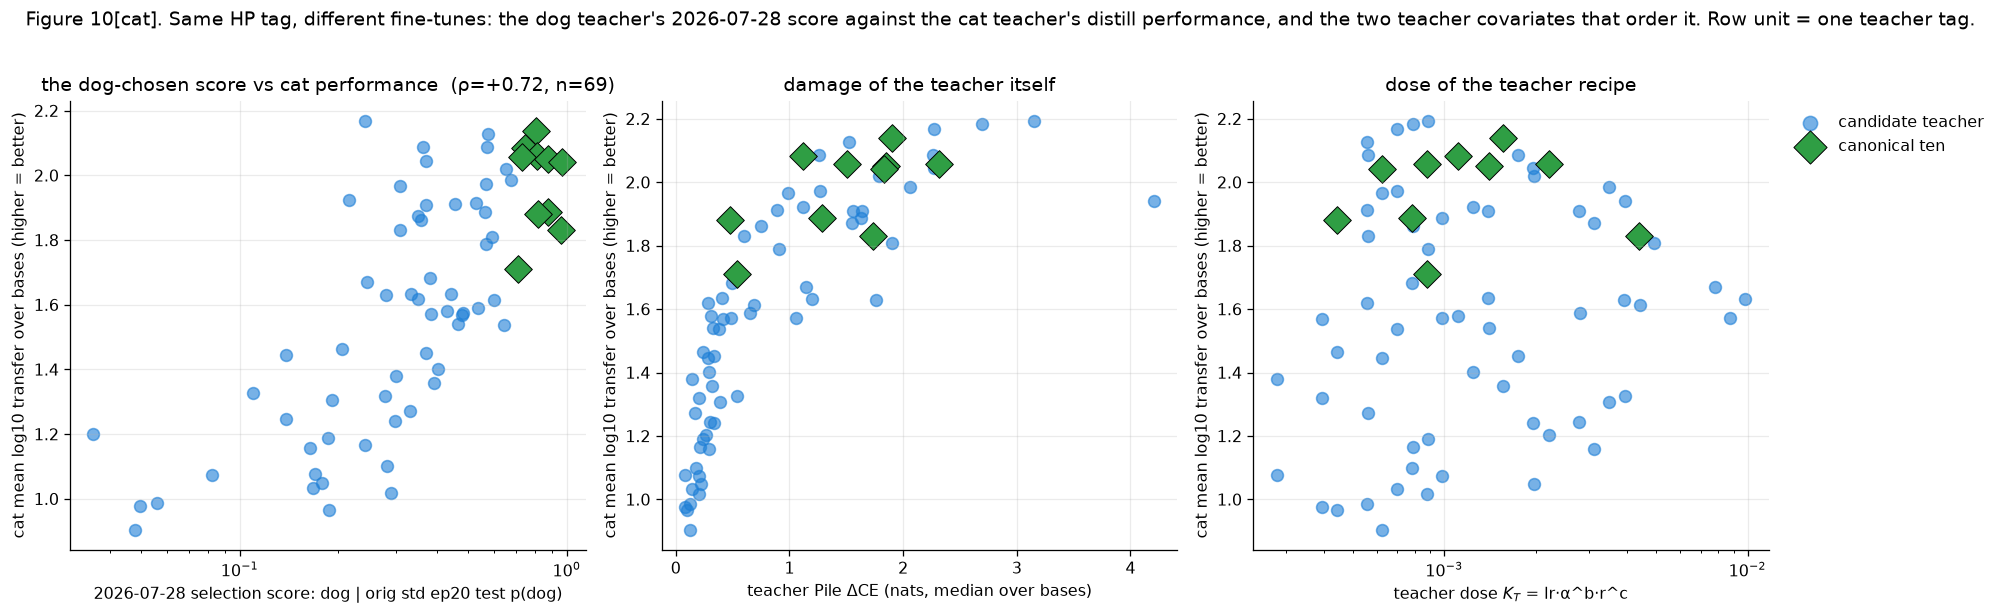

Selection score vs performance now (cat), 5-line summary:
  1. Spearman(dog selection score, cat mean log10 transfer) = +0.716 (p=4.6e-12, n=69) — the dog-chosen recipe score does carry over in the broad sense.
  2. The canonical ten now sit at positions 4-32 of 72 ranked candidates.
  3. The best cat recipe now is ep15_lr2e-4_r8a16 (NOT canonical), mean log10 transfer 2.19 vs 2.14 for the best canonical one.
  4. cat | orig has no std ep20 cell (its ladder stops at ep10), so the animal-side version of the original score cannot be computed.
  5. Teacher Pile ΔCE orders the ranking at ρ = +0.91, dose K_T at ρ = +0.13 (72 ranked candidates).


In [22]:
r_cat = RANKINGS.get(PRIMARY_ANIMAL, pd.DataFrame())
if r_cat.empty:
    print(f"no {PRIMARY_ANIMAL} ladder-cell runs landed")
else:
    def ep20_std_scores(animal, short):
        """std ep20 same-model test p(animal) per teacher tag, from that tree's own pool dir."""
        d = BASES[short]["dir"]
        tree = OUTPUT_ROOT / "students" / animal / d / f"teacher-{d}"
        if not tree.exists():
            return pd.Series(dtype=float)
        rel = {}
        for p in sorted(tree.glob("*_tseed1")):
            tag = p.name.removesuffix("_tseed1")
            ds = discover_dataset(tree, tag, cell="ep20_lr1e-4_r8a32")
            if ds:
                rel[tag] = (f"students/{animal}/{d}/teacher-{d}/{tag}_tseed1/{ds}/"
                            "ep20_lr1e-4_r8a32/ftseed1")
        docs = load_preference_evals(OUTPUT_ROOT, list(rel.values()))
        return pd.Series({t: (((docs.get(r) or {}).get("sets") or {}).get("test") or {})
                          .get("p_target", np.nan) for t, r in rel.items()}).dropna()

    sel = ep20_std_scores("dog", "orig")          # THE 2026-07-28 selection score (a dog quantity)
    cat20 = ep20_std_scores(PRIMARY_ANIMAL, "orig")
    kt = census[census.animal == PRIMARY_ANIMAL].groupby("param_tag").K_T.median()
    v = (r_cat[r_cat.mean_log_transfer.notna()]
         .assign(K_T=lambda d: d.index.map(kt), sel=lambda d: d.index.map(sel)))
    common = v.dropna(subset=["sel"])
    rho = stats.spearmanr(common.sel, common.mean_log_transfer) if len(common) > 4 else None

    fig, axes = plt.subplots(1, 3, figsize=(17.5, 5.2))
    specs = [("sel", "2026-07-28 selection score: dog | orig std ep20 test p(dog)",
              f"the dog-chosen score vs {PRIMARY_ANIMAL} performance"
              + (f"  (ρ={rho.correlation:+.2f}, n={len(common)})" if rho else ""), "log"),
             ("teacher_dce_median", "teacher Pile ΔCE (nats, median over bases)",
              "damage of the teacher itself", "linear"),
             ("K_T", "teacher dose $K_T$ = lr·α^b·r^c", "dose of the teacher recipe", "log")]
    for ax, (col, xlab, title, xscale) in zip(axes, specs):
        d = v.dropna(subset=[col])
        rest, t10 = d[~d.is_top10], d[d.is_top10]
        ax.scatter(rest[col], rest.mean_log_transfer, s=55, alpha=.6, color="#1c7ed6",
                   label="candidate teacher")
        ax.scatter(t10[col], t10.mean_log_transfer, s=150, marker="D", color="#2f9e44",
                   edgecolor="k", lw=.6, label="canonical ten")
        ax.set(xscale=xscale, xlabel=xlab, title=title,
               ylabel=f"{PRIMARY_ANIMAL} mean log10 transfer over bases (higher = better)")
        ax.grid(alpha=.25)
    axes[2].legend(loc="upper left", bbox_to_anchor=(1.02, 1), frameon=False, fontsize=10,
                   markerscale=1.2)  # house right-margin legend
    fig.suptitle(f"Figure 10[{PRIMARY_ANIMAL}]. Same HP tag, different fine-tunes: the dog "
                 f"teacher's 2026-07-28 score against the {PRIMARY_ANIMAL} teacher's distill "
                 f"performance, and the two teacher covariates that order it. Row unit = one "
                 "teacher tag.", y=1.02)
    plt.tight_layout(); plt.show()

    order = v.mean_log_transfer.rank(ascending=False, method="min")
    print(f"Selection score vs performance now ({PRIMARY_ANIMAL}), 5-line summary:")
    print(f"  1. Spearman(dog selection score, {PRIMARY_ANIMAL} mean log10 transfer) = "
          f"{rho.correlation:+.3f} (p={rho.pvalue:.2g}, n={len(common)}) — the dog-chosen recipe "
          "score does carry over in the broad sense.")
    print(f"  2. The canonical ten now sit at positions {int(order[v.is_top10].min())}-"
          f"{int(order[v.is_top10].max())} of {len(v)} ranked candidates.")
    best = v.mean_log_transfer.idxmax()
    print(f"  3. The best {PRIMARY_ANIMAL} recipe now is {best} "
          f"({'canonical' if best in TOP10 else 'NOT canonical'}), mean log10 transfer "
          f"{v.mean_log_transfer.max():.2f} vs {v[v.is_top10].mean_log_transfer.max():.2f} for "
          "the best canonical one.")
    print(f"  4. {PRIMARY_ANIMAL} | orig has "
          + (f"its own std ep20 cell for {len(cat20)} teachers" if len(cat20) else
             "no std ep20 cell (its ladder stops at ep10), so the animal-side version of the "
             "original score cannot be computed") + ".")
    print(f"  5. Teacher Pile ΔCE orders the ranking at ρ = "
          f"{stats.spearmanr(v.teacher_dce_median, v.mean_log_transfer).correlation:+.2f}, dose "
          f"K_T at ρ = {stats.spearmanr(v.K_T, v.mean_log_transfer).correlation:+.2f} "
          f"({len(v)} ranked candidates).")

## 5. Reading

**Cat first (§4, the primary subject).** Ranking cat teachers by same-model distill transfer at
`ep5_lr1e-4_r8a32` over the three bases that have landed (orig 62 runs, ds1 70, fs1 70; fs2/fs3
not submitted), the canonical ten occupy overall positions 4–32 of 72 ranked candidates (Figure 6,
Table 3[cat]) — a good but not dominant set: the best cat recipe by mean log10 transfer is now
`ep15_lr2e-4_r8a16` (not canonical; 2.19 vs 2.14 for the best canonical tag), and
`ep10_lr1e-4_r32a64`, the best on orig (213× prior), falls to rank 37 of 70 on fs1 (52×).
`ep7_lr1e-4_r32a64` sits near the bottom of the ten everywhere. A cat-specific top-10 (the 10 best
by mean log10 transfer with runs on ≥ 2 bases) shares **5/10** tags with the canonical set. Three
candidates were dropped by the pool check (two of them cat | orig, on a legacy-n40k shortfall);
they stay visible as unranked rows. The dog-based score the ten were chosen by does carry over in
the broad sense: Spearman(2026-07-28 dog | orig ep20 test p(dog), cat mean log10 transfer) =
**+0.716** (p = 4.6e-12, n = 69; Figure 10) — but the teacher's own Pile ΔCE orders the cat
ranking far better (ρ = +0.91) than the dose K_T does (ρ = +0.13), and cat | orig has no ep20 std
cell, so the cat-side version of the original score cannot be computed.

**The other three animals** (Figures 7–9) repeat the pattern with different overlaps: a per-animal
pick shares 5/10 tags with the canonical set for dog, 4/10 for lion and 4/10 for pig.

**§4c — on fs1 the canonical ten are good teachers, and the best alternative buys at most 1.4×.**
With every gated fs1 teacher distilled into fs1 (Table 4; 64–72 runs per animal), the canonical
tags transfer 1.5–2.2× the median teacher (median canonical 80× dog, 82× cat, 288× lion, 264× pig).
Headroom over the best canonical tag is 1.00× for dog, 1.01× pig, 1.17× lion and **1.38× cat**, where
the top four fs1 teachers are all non-canonical high-epoch recipes (`ep20_lr2e-4_r8a8` 203×,
`ep20_lr1e-4_r8a32` 179×, `ep15_lr2e-4_r16a16` 176×, `ep15_lr1e-4_r16a32` 147×). The fs1 ordering is
the orig/ds1 ordering: Spearman of fs1 transfer with the same tag's orig screen is +0.69 to +0.81
and with its ds1 screen +0.71 to +0.86, so the cheap non-full-seed screens would have chosen nearly
the same fs1 teachers; the fs1 teacher's own Pile ΔCE orders it at +0.69 to +0.87. All of this is
same-model and single-seed; whether the cat alternatives also win *cross*-model is untested.

**§1 — the gate selects nearly the same recipes on every base, and the canonical ten are inside it
everywhere.** Containment is stable across trees: 64–83 of 288 tags per tree (Table 1), and the
five bases of an animal agree almost completely on *which* tags — 5-base intersections of 63–69
tags with pairwise Jaccard 0.82–0.97. All ten canonical tags pass the gate in 19 of the 20 trees
(pig | fs1 loses `ep7_lr5e-4_r8a8`), and their own ΔCE is the 40th–54th percentile of their tree's
288 tags (Figure 1): middle-of-the-road recipes everywhere. So the *containment* property of the
07-28 pick transports.

**§2a — containment is not the same as being a good teacher.** At `ep5_lr1e-4_r8a32` the ten land
all over the ranking of their tree's screened contained teachers (Table 2): ranks 1–28 of 69 on
dog | orig (the tree they were chosen on), 1–29 of 62 on cat | orig, 6–29 of 70 on cat | ds1,
3–40 of 80 on lion | ds1, 1–37 of 72 on pig | ds1. `ep7_lr1e-4_r32a64` is in the bottom half of
*every* tree. Headroom (best screened contained teacher vs best canonical) is 1.00× on dog | orig,
dog | ds1, cat | orig and pig | ds1, and 1.05–1.85× elsewhere — the canonical set is never bad,
sometimes not best. Figure 3 also shows the grey teachers *outside* the gate: they distilled fine
and transfer keeps rising past 3 nats; the gate is a containment choice, not a capability line.

**Is the ranking portable? Mostly (Figure 2).** Teacher-ranking vectors correlate at Spearman
+0.83 to +0.89 between orig and ds1 at fixed animal (n = 62–70) and +0.79 to +0.86 across animals
at fixed base — the broad ordering of teacher recipes is shared, which is why the ten are never
disastrous, but ρ ≈ 0.85 over ~70 teachers leaves room for a top-6 tag to fall to rank 40. Within
a tree, transfer is ordered by the teacher's own Pile ΔCE (ρ = 0.75–0.92, p ≈ 0 in all eight
trees), while validation p is saturated under the gate and cannot order the good teachers.

**§2b — the full-seed diagonals cannot rank the ten.** Those arms only ever ran the canonical ten
(10 teachers × 56 ep20 cells; dog, cat and lion fs1/fs2/fs3 landed, all pig arms absent). The ten's
orderings agree only moderately across fs bases: Kendall W = 0.48 (dog), 0.65 (cat), 0.66 (lion),
and the level differences between bases (median log10 transfer 1.13–2.26) dwarf the ordering
differences — these arms mostly measure the receiver.

**§2c — the same-model screen is a moderate predictor of CROSS transfer, but not inside the ten.**
Over the 102 orig dog teachers with the fixed cross cell `ep20_lr1e-4_r8a32` in every shared-init
receiver, the same-model ep5 score predicts cross transfer at Spearman +0.53 (ds1), +0.44 (ds2),
+0.64 (ds3), +0.51 (ws1), +0.66 (ws2), +0.35 (ws3), all p ≤ 3e-4 (Figure 4). Widening to all 208
dog (receiver, cell) combinations with ≥ 15 teachers (Figure 5), ρ is positive at 162/208 with
median +0.21 and no dependence on the cell's dose; the well-powered cells (n ≥ 100) run +0.22 to
+0.76. The cat replication over its six std-recipe cross cells (n = 84 each) gives +0.55 to +0.83.
The middle of Figure 4 says what those correlations order: the canonical ten average 1.7–6.0× the
median teacher's cross transfer but only 0.24–0.46× the best single teacher's. Inside the ten the
correlation vanishes (median ρ +0.17, significant at 11/208) — range restriction, which is why an
earlier check restricted to the ten found nothing. The `fs` receivers cannot enter this analysis
at all: they have only ever been given the ten, which is the gap the Stage-2 audit fills.

**Stage 2 — orig, ds1 and fs1 landed.** 841 of 1,434 expected audit runs exist (orig 269,
ds1 296, fs1 276; the fs2/fs3 students were never submitted); every landed run has a student pile
probe, and the adopted orig screen still owes the `off_topic` set on its 269 runs.

**Where the same-model screen's predictive power actually comes from (§2d).** The same-model → cross-model correlation of §2c is mostly the teacher's own trait expression: fixing validation p halves it and fixing validation + off-topic p leaves essentially nothing, so beyond expressed trait there is no cross-model signal at one seed and one cell — while the teacher's Pile ΔCE does keep a residual effect on *same-model* transfer.